In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [41]:
file_path= "/workspace/data/raw/02_CortexHR_AI_ML_Dataset.xlsx" 
df=pd.read_excel(file_path,sheet_name="attrition_dataset")

In [42]:
df.head()

,row_id,employee_id,observation_date,department_id,role_id,job_level,work_location,work_mode,employment_type,highest_education,...,paid_leave_days_6m,dept_attrition_rate_prior_12m,left_within_12m,voluntary_left_within_12m,source,exit_date,resignation_date,exit_reason,exit_interview_done,fnf_settlement_amount
0,1,EMP-0002,2025-09-30,D08,R047,4,Pune,Remote,Permanent,B.E. Computer Science,...,5,0.2353,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
1,2,EMP-0004,2025-09-30,D03,R017,3,Erode,Hybrid,Permanent,MCA,...,4,0.0556,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2,3,EMP-0011,2025-09-30,D07,R039,1,Kochi,Hybrid,Permanent,M.A. Social Work,...,7,0.0000,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
3,4,EMP-0012,2025-09-30,D01,R004,2,Chennai,Onsite,Permanent,B.Tech Information Technology,...,8,0.1448,1,1,master_employee_snapshot,2026-04-23,2026-03-24,Work-Life Balance,Y,117098.85
4,5,EMP-0013,2025-09-30,D04,R023,2,Chennai,Onsite,Permanent,B.E. Mechanical,...,7,0.2051,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN


In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2389 entries, 0 to 2388
Data columns (total 42 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   row_id                           2389 non-null   int64         
 1   employee_id                      2389 non-null   str           
 2   observation_date                 2389 non-null   datetime64[us]
 3   department_id                    2389 non-null   str           
 4   role_id                          2389 non-null   str           
 5   job_level                        2389 non-null   int64         
 6   work_location                    2389 non-null   str           
 7   work_mode                        2389 non-null   str           
 8   employment_type                  2389 non-null   str           
 9   highest_education                2374 non-null   str           
 10  tenure_months                    2389 non-null   int64         
 11  to

In [47]:
df.shape

(2389, 42)

In [48]:
df.isnull().sum()

row_id                                0
employee_id                           0
observation_date                      0
department_id                         0
role_id                               0
job_level                             0
work_location                         0
work_mode                             0
employment_type                       0
highest_education                    15
tenure_months                         0
total_experience_years                0
previous_employers_count              0
commute_distance_km                  55
annual_fixed_pay                      0
comp_ratio                            0
raises_received                       0
last_raise_pct                      202
months_since_last_raise               0
promotions_received                   0
months_since_last_promotion        1459
internal_transfers                    0
last_performance_rating             182
last_engagement_score               528
manager_changes_12m                   0


In [49]:
#missing summary percentage 

In [50]:
missing_val=pd.DataFrame({ 
                          "missing_count":df.isna().sum(),
                          "missing_percentage":df.isna().mean()*100,
                         })

In [51]:
missing_val = missing_val.reset_index(names="column_name")


In [52]:
missing_val=missing_val[missing_val["missing_count"]>0].sort_values(by="missing_percentage",ascending=False)

In [53]:
missing_val

,column_name,missing_count,missing_percentage
38,resignation_date,2068,86.563416
37,exit_date,2040,85.391377
39,exit_reason,2040,85.391377
41,fnf_settlement_amount,2040,85.391377
40,exit_interview_done,2040,85.391377
20,months_since_last_promotion,1459,61.071578
23,last_engagement_score,528,22.101298
17,last_raise_pct,202,8.455421
22,last_performance_rating,182,7.618250
13,commute_distance_km,55,2.302219


In [54]:
#Duplicate-Record Audit

In [55]:
df.duplicated().sum()

np.int64(0)

In [56]:
duplicate_count = int(df.duplicated().sum())
total_records = len(df)


In [57]:
if total_records >0:
    duplicate_percentage=(duplicate_count/total_records)*100
else:
    duplicate_percentage=0

In [58]:
duplicate_audit=pd.DataFrame=({
                            "Metrics":["Total_records",
                                      "duplicate records",
                                       "duplicate_percent"],
                            "Values":[total_records,
                                      duplicate_count,
                                      round(duplicate_percentage,2)]
})

In [59]:
duplicate_audit

{'Metrics': ['Total_records', 'duplicate records', 'duplicate_percent'],
 'Values': [2389, 0, 0.0]}

In [60]:
# We need to check the employee id and observastion date because the same employee may legitimately have multiple observations

In [61]:
df

,row_id,employee_id,observation_date,department_id,role_id,job_level,work_location,work_mode,employment_type,highest_education,...,paid_leave_days_6m,dept_attrition_rate_prior_12m,left_within_12m,voluntary_left_within_12m,source,exit_date,resignation_date,exit_reason,exit_interview_done,fnf_settlement_amount
0,1,EMP-0002,2025-09-30,D08,R047,4,Pune,Remote,Permanent,B.E. Computer Science,...,5,0.2353,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
1,2,EMP-0004,2025-09-30,D03,R017,3,Erode,Hybrid,Permanent,MCA,...,4,0.0556,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2,3,EMP-0011,2025-09-30,D07,R039,1,Kochi,Hybrid,Permanent,M.A. Social Work,...,7,0.0000,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
3,4,EMP-0012,2025-09-30,D01,R004,2,Chennai,Onsite,Permanent,B.Tech Information Technology,...,8,0.1448,1,1,master_employee_snapshot,2026-04-23,2026-03-24,Work-Life Balance,Y,117098.85
4,5,EMP-0013,2025-09-30,D04,R023,2,Chennai,Onsite,Permanent,B.E. Mechanical,...,7,0.2051,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2384,2385,EMP-0238,2025-09-30,D01,R004,2,Chennai,Remote,Permanent,M.Tech,...,18,0.1448,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2385,2386,EMP-0483,2025-09-30,D09,R053,4,Bengaluru,Onsite,Permanent,MBA,...,1,0.2069,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2386,2387,EMP-0060,2025-09-30,D01,R006,3,Bengaluru,Hybrid,Permanent,MCA,...,1,0.1448,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2387,2388,EMP-0237,2025-09-30,D07,R040,2,Chennai,Remote,Permanent,B.Sc,...,9,0.0000,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN


In [62]:
duplicate_employee_row=df['employee_id'].duplicated().sum()
unique_employees = df["employee_id"].nunique()
duplicate_employee_dates=df.duplicated(subset=["employee_id","observation_date"]).sum()

In [63]:
print("Duplicate employee-date rows:", duplicate_employee_dates)
print("Repeated employee ID rows:", duplicate_employee_row)
print("Unique employees:", unique_employees)

Duplicate employee-date rows: 6
Repeated employee ID rows: 6
Unique employees: 2383


In [64]:
duplicate_employee_date_records = df[df.duplicated(
        subset=["employee_id", "observation_date"],keep=False)].sort_values(["employee_id", "observation_date"])

In [65]:
duplicate_employee_date_records

,row_id,employee_id,observation_date,department_id,role_id,job_level,work_location,work_mode,employment_type,highest_education,...,paid_leave_days_6m,dept_attrition_rate_prior_12m,left_within_12m,voluntary_left_within_12m,source,exit_date,resignation_date,exit_reason,exit_interview_done,fnf_settlement_amount
26,27,EMP-0060,2025-09-30,D01,R006,3,Bengaluru,Hybrid,Permanent,MCA,...,1,0.1448,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2386,2387,EMP-0060,2025-09-30,D01,R006,3,Bengaluru,Hybrid,Permanent,MCA,...,1,0.1448,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
100,101,EMP-0237,2025-09-30,D07,R040,2,Chennai,Remote,Permanent,B.Sc,...,9,0.0000,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2387,2388,EMP-0237,2025-09-30,D07,R040,2,Chennai,Remote,Permanent,B.Sc,...,9,0.0000,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
101,102,EMP-0238,2025-09-30,D01,R004,2,Chennai,Remote,Permanent,M.Tech,...,18,0.1448,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2384,2385,EMP-0238,2025-09-30,D01,R004,2,Chennai,Remote,Permanent,M.Tech,...,18,0.1448,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
150,151,EMP-0325,2025-09-30,D03,R019,4,Chennai,Hybrid,Permanent,MCA,...,1,0.0556,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2383,2384,EMP-0325,2025-09-30,D03,R019,4,Chennai,Hybrid,Permanent,MCA,...,1,0.0556,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
250,251,EMP-0483,2025-09-30,D09,R053,4,Bengaluru,Onsite,Permanent,MBA,...,1,0.2069,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2385,2386,EMP-0483,2025-09-30,D09,R053,4,Bengaluru,Onsite,Permanent,MBA,...,1,0.2069,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN


In [66]:
df['row_id'].duplicated().sum()

np.int64(0)

In [67]:
#Outlier detection and calculating

In [68]:
numerical_columns=df.select_dtypes(include=np.number).columns.tolist()
numerical_columns

['row_id',
 'job_level',
 'tenure_months',
 'total_experience_years',
 'previous_employers_count',
 'commute_distance_km',
 'annual_fixed_pay',
 'comp_ratio',
 'raises_received',
 'last_raise_pct',
 'months_since_last_raise',
 'promotions_received',
 'months_since_last_promotion',
 'internal_transfers',
 'last_performance_rating',
 'last_engagement_score',
 'manager_changes_12m',
 'training_hours_12m',
 'attendance_rate_3m',
 'late_arrivals_3m',
 'avg_overtime_hours_per_month_3m',
 'avg_hours_worked_3m',
 'wfh_share_3m',
 'unpaid_leave_days_6m',
 'paid_leave_days_6m',
 'dept_attrition_rate_prior_12m',
 'left_within_12m',
 'voluntary_left_within_12m',
 'fnf_settlement_amount']

In [69]:
df[numerical_columns].nunique()

row_id                             2389
job_level                             6
tenure_months                       148
total_experience_years              224
previous_employers_count              7
commute_distance_km                 372
annual_fixed_pay                   2364
comp_ratio                          585
raises_received                       8
last_raise_pct                      184
months_since_last_raise              48
promotions_received                   8
months_since_last_promotion          94
internal_transfers                    3
last_performance_rating               5
last_engagement_score                38
manager_changes_12m                   5
training_hours_12m                  593
attendance_rate_3m                 1051
late_arrivals_3m                     27
avg_overtime_hours_per_month_3m     390
avg_hours_worked_3m                 181
wfh_share_3m                        619
unpaid_leave_days_6m                 20
paid_leave_days_6m                   23


In [70]:
exclude_columns=["row_id","employee_id","left_within_12m","voluntary_left_within_12m"]                         

In [71]:
special_check_columns = ["job_level","last_performance_rating","last_engagement_score","attendance_rate_3m","wfh_share_3m","dept_attrition_rate_prior_12m"
]

In [72]:
outliers_columns=[]
for i in numerical_columns:
    if i not in exclude_columns and i not in special_check_columns:
        outliers_columns.append(i)

In [73]:
outliers_columns

['tenure_months',
 'total_experience_years',
 'previous_employers_count',
 'commute_distance_km',
 'annual_fixed_pay',
 'comp_ratio',
 'raises_received',
 'last_raise_pct',
 'months_since_last_raise',
 'promotions_received',
 'months_since_last_promotion',
 'internal_transfers',
 'manager_changes_12m',
 'training_hours_12m',
 'late_arrivals_3m',
 'avg_overtime_hours_per_month_3m',
 'avg_hours_worked_3m',
 'unpaid_leave_days_6m',
 'paid_leave_days_6m',
 'fnf_settlement_amount']

In [74]:
outlier_results=[]

In [172]:
for col in outliers_columns:
    Q1= df[col].quantile(0.25)
    Q3= df[col].quantile(0.75)
    IQR=Q3-Q1
    lower_bound=Q1-1.5*IQR
    upper_bound=Q3+1.5*IQR
    outlier_count=(
        (df[col]<lower_bound)|
         (df[col]>upper_bound)
    ).sum()
    outlier_results.append({
        "column": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outlier_count,
        "outlier_percentage":(outlier_count / df[col].notna().sum()) * 100 if df[col].notna().sum() > 0 else 0
        })


In [173]:
#outliers_summary=pd.DataFrame(outlier_results)


In [174]:
outliers_summary = pd.DataFrame(outlier_results)
outliers_summary=outliers_summary.sort_values(by="outlier_percentage",ascending=False)
outliers_summary

,column,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
35,avg_overtime_hours_per_month_3m,0.000,0.000,0.000,0.0000,0.000000e+00,446,18.668899
15,avg_overtime_hours_per_month_3m,0.000,0.000,0.000,0.0000,0.000000e+00,446,18.668899
11,internal_transfers,0.000,0.000,0.000,0.0000,0.000000e+00,189,7.911260
31,internal_transfers,0.000,0.000,0.000,0.0000,0.000000e+00,189,7.911260
23,commute_distance_km,6.200,15.575,9.375,-7.8625,2.963750e+01,141,6.041131
3,commute_distance_km,6.200,15.575,9.375,-7.8625,2.963750e+01,141,5.902051
29,promotions_received,0.000,1.000,1.000,-1.5000,2.500000e+00,138,5.776476
9,promotions_received,0.000,1.000,1.000,-1.5000,2.500000e+00,138,5.776476
39,fnf_settlement_amount,42566.900,143303.600,100736.700,-108538.1500,2.944087e+05,19,5.444126
13,training_hours_12m,14.400,33.200,18.800,-13.8000,6.140000e+01,99,4.143993


In [78]:
import importlib
import pandas as pd

pd = importlib.reload(pd)

In [79]:
print("pd type:", type(pd))
print("DataFrame type:", type(pd.DataFrame))
print("DataFrame value:", pd.DataFrame)

pd type: <class 'module'>
DataFrame type: <class 'type'>
DataFrame value: <class 'pandas.DataFrame'>


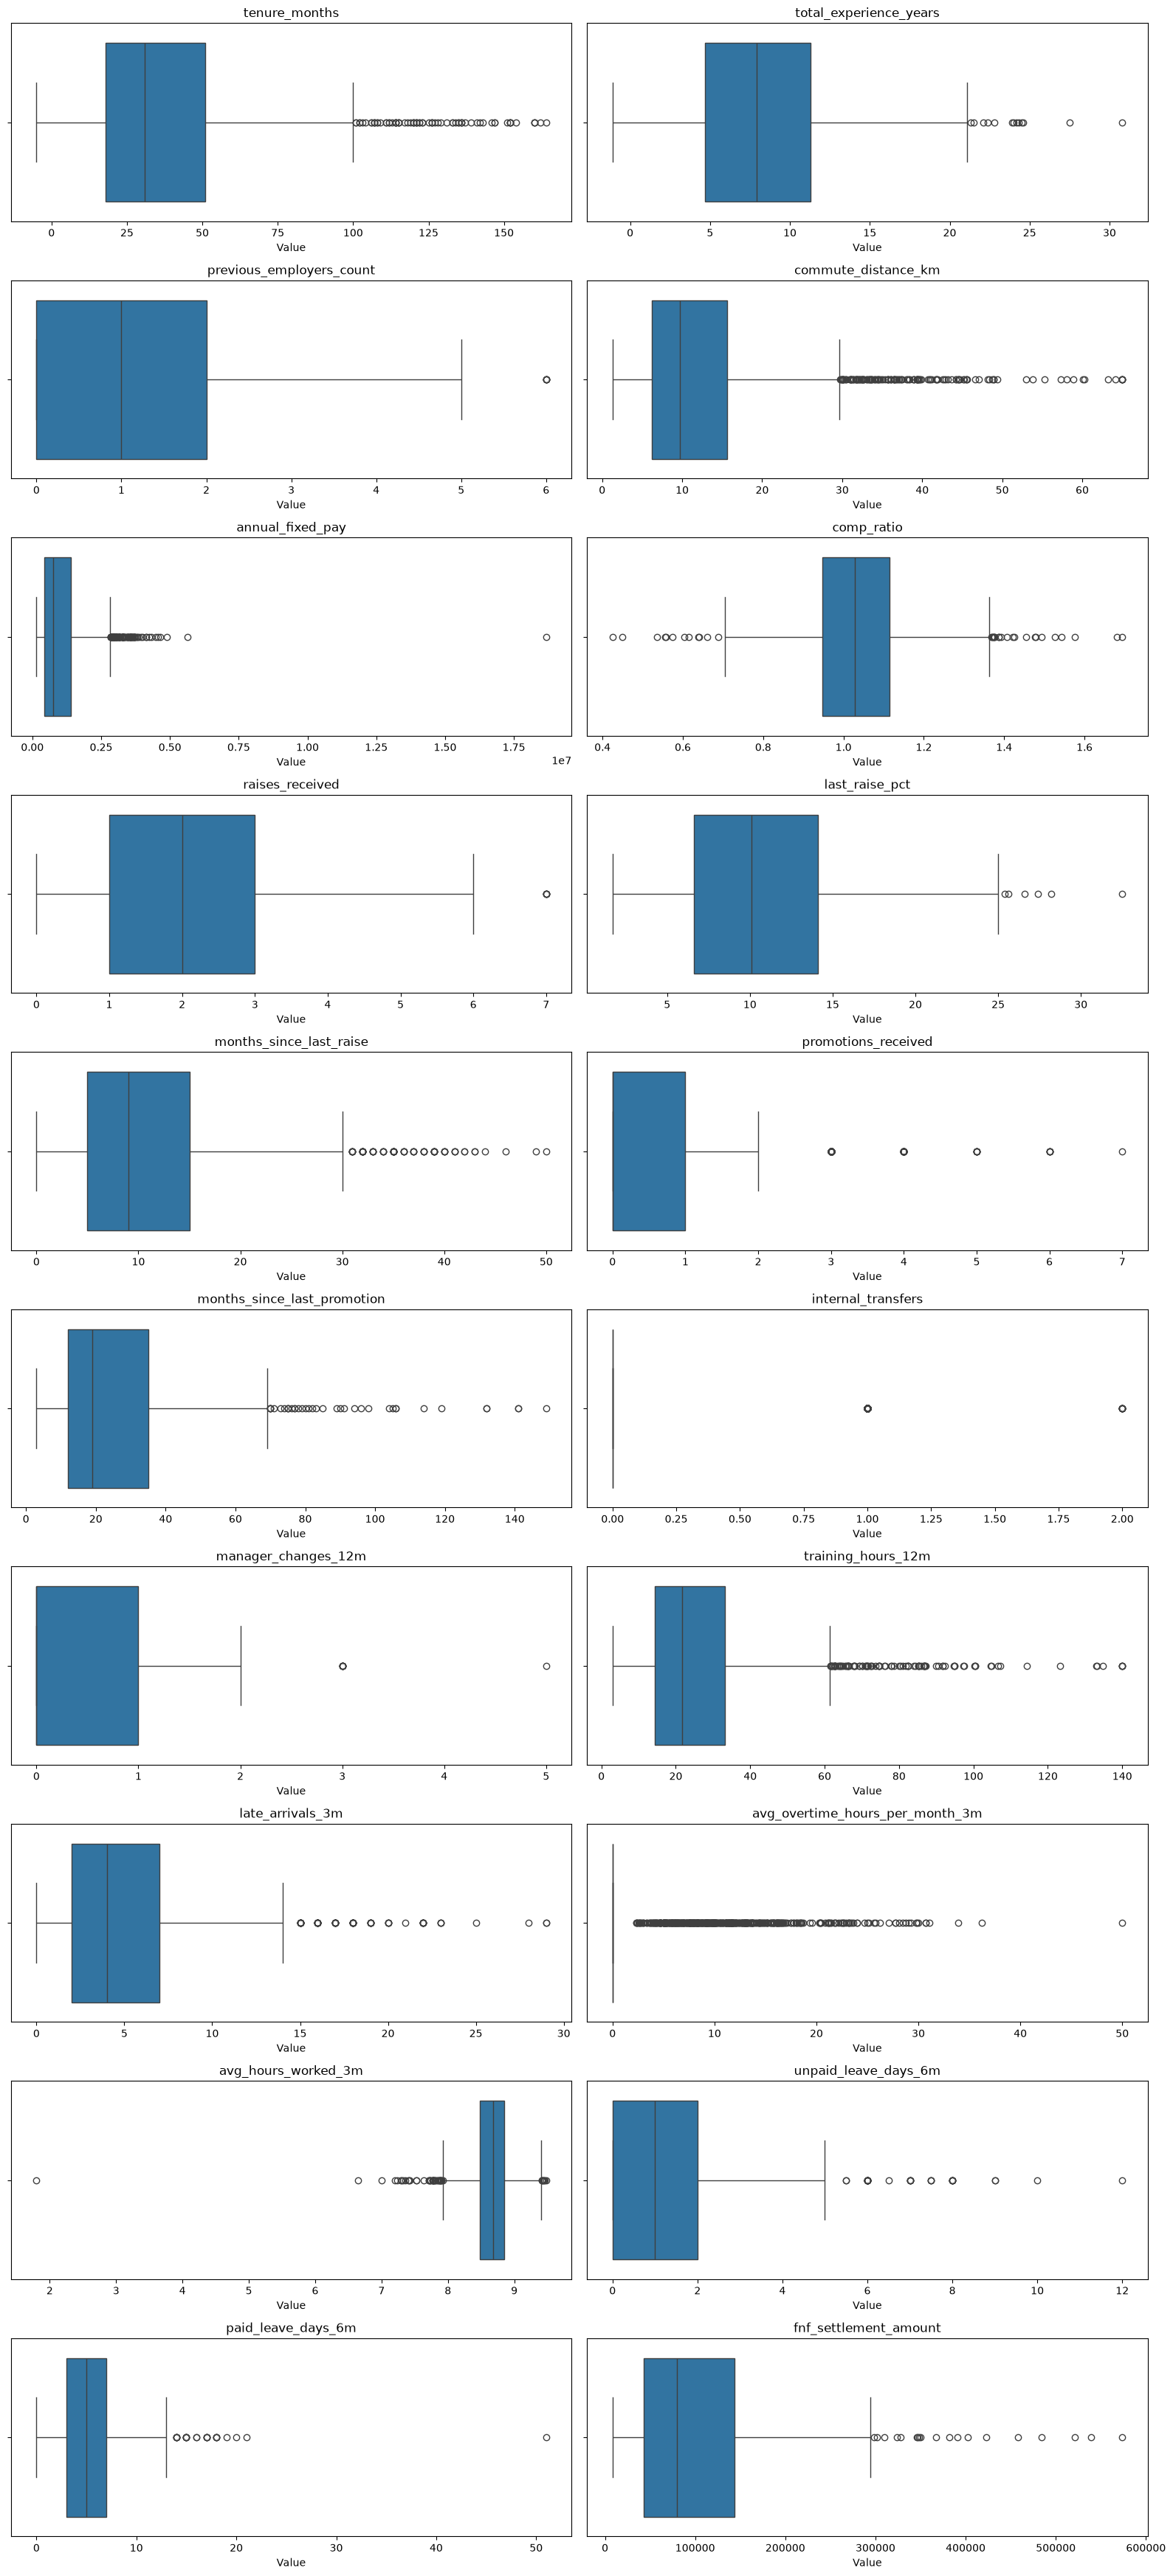

In [82]:
n_cols = 2
n_rows = (len(outliers_columns) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(16, n_rows * 3.5)
)
axes = axes.flatten()
for i, col in enumerate(outliers_columns):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("Value")
for i in range(len(outliers_columns), len(axes)):
    axes[i].set_visible(False)
plt.tight_layout()
plt.show()

In [83]:
#Impossible values  

In [ ]:
#negative tenure, age below 18, and percentages above 100%.

In [84]:
df.columns.tolist()


['row_id',
 'employee_id',
 'observation_date',
 'department_id',
 'role_id',
 'job_level',
 'work_location',
 'work_mode',
 'employment_type',
 'highest_education',
 'tenure_months',
 'total_experience_years',
 'previous_employers_count',
 'commute_distance_km',
 'annual_fixed_pay',
 'comp_ratio',
 'raises_received',
 'last_raise_pct',
 'months_since_last_raise',
 'promotions_received',
 'months_since_last_promotion',
 'internal_transfers',
 'last_performance_rating',
 'last_engagement_score',
 'manager_changes_12m',
 'training_hours_12m',
 'attendance_rate_3m',
 'late_arrivals_3m',
 'avg_overtime_hours_per_month_3m',
 'avg_hours_worked_3m',
 'wfh_share_3m',
 'unpaid_leave_days_6m',
 'paid_leave_days_6m',
 'dept_attrition_rate_prior_12m',
 'left_within_12m',
 'voluntary_left_within_12m',
 'source',
 'exit_date',
 'resignation_date',
 'exit_reason',
 'exit_interview_done',
 'fnf_settlement_amount']

In [85]:
impossible_checks={
    "negative_tenure":df["tenure_months"]<0,
    "negative_total_experience": df["total_experience_years"] < 0,
    "negative_commute_distance": df["commute_distance_km"] < 0,
    "negative_annual_fixed_pay": df["annual_fixed_pay"] < 0,
    "negative_training_hours": df["training_hours_12m"] < 0,
    "negative_hours_worked": df["avg_hours_worked_3m"] < 0,
    "negative_unpaid_leave_days": df["unpaid_leave_days_6m"] < 0,
    "negative_paid_leave_days": df["paid_leave_days_6m"] < 0,
    "negative_fnf_settlement": df["fnf_settlement_amount"] < 0,
}
impossible_results=[]

for check_name,condition in impossible_checks.items():
    impossible_results.append({
        "check":check_name,
        "violation_count":int(condition.sum()),
        "violation_perccentage":round(condition.mean()*100,3)
    })
    

In [86]:
impossible_summary=pd.DataFrame(impossible_results)

In [87]:
impossible_summary=impossible_summary.sort_values(by="violation_perccentage",ascending=False)

In [88]:
impossible_summary

,check,violation_count,violation_perccentage
1,negative_total_experience,10,0.419
0,negative_tenure,4,0.167
2,negative_commute_distance,0,0.000
3,negative_annual_fixed_pay,0,0.000
4,negative_training_hours,0,0.000
5,negative_hours_worked,0,0.000
6,negative_unpaid_leave_days,0,0.000
7,negative_paid_leave_days,0,0.000
8,negative_fnf_settlement,0,0.000


In [ ]:
#check percentage/rate columns

In [92]:
df[["attendance_rate_3m","wfh_share_3m","dept_attrition_rate_prior_12m"]].describe()

,attendance_rate_3m,wfh_share_3m,dept_attrition_rate_prior_12m
count,2389.000000,2389.000000,2389.000000
mean,0.910462,0.378770,0.152027
std,0.047406,0.319722,0.046886
min,0.203100,-0.096000,0.000000
25%,0.887100,0.055000,0.127300
50%,0.912800,0.393000,0.150100
75%,0.937500,0.473000,0.181600
max,1.120000,1.088000,0.289700


In [93]:
rate_columns=["attendance_rate_3m","wfh_share_3m","dept_attrition_rate_prior_12m"]

In [94]:
rate_result=[]
for col in rate_columns:
    below_zero=df[col]<0
    above_one=df[col]>1

    rate_result.append({
     "column":col,
     "below_0":int(below_zero.sum()),
    "above_0":int(above_one.sum()),
    "total_violation":int((below_zero | above_one).sum())
    })
rate_summary=pd.DataFrame(rate_result)
rate_summary

,column,below_0,above_0,total_violation
0,attendance_rate_3m,0,2,2
1,wfh_share_3m,190,23,213
2,dept_attrition_rate_prior_12m,0,0,0


In [95]:
for col in ["attendance_rate_3m", "wfh_share_3m"]:
    invalid_mask = (df[col] < 0) | (df[col] > 1)
    print(f"\n{col}: {invalid_mask.sum()} violations")
    display(
        df.loc[invalid_mask, ["employee_id", col]]
        .sort_values(by=col)
    )


attendance_rate_3m: 2 violations


,employee_id,attendance_rate_3m
430,HIST-0048,1.12
1233,HIST-0851,1.12



wfh_share_3m: 213 violations


,employee_id,wfh_share_3m
1152,HIST-0770,-0.096
625,HIST-0243,-0.093
2352,HIST-1970,-0.093
2108,HIST-1726,-0.088
2333,HIST-1951,-0.088
...,...,...
1380,HIST-0998,1.043
830,HIST-0448,1.051
1788,HIST-1406,1.052
1619,HIST-1237,1.063


In [96]:
import pandas as pd
file_path = "/workspace/data/raw/02_CortexHR_AI_ML_Dataset.xlsx"
data_dictionary = pd.read_excel(
    file_path,
    sheet_name="data_dictionary"
)
data_dictionary.head()

,sheet,column,data_type,description,null_count,null_percent,distinct_values,example
0,attrition_dataset,row_id,integer,Row number in the sheet.,0,0.0,2389,1
1,attrition_dataset,employee_id,text,Unique employee code (EMP-0001 ...). Same code...,0,0.0,2383,EMP-0002
2,attrition_dataset,observation_date,date,Date the features were measured (30 Sep 2025 f...,0,0.0,1135,2025-09-30
3,attrition_dataset,department_id,text,Department code (D00 Executive ... D10 Legal &...,0,0.0,10,D08
4,attrition_dataset,role_id,text,Job role code from the roles table.,0,0.0,48,R047


In [97]:
data_dictionary

,sheet,column,data_type,description,null_count,null_percent,distinct_values,example
0,attrition_dataset,row_id,integer,Row number in the sheet.,0,0.0,2389,1
1,attrition_dataset,employee_id,text,Unique employee code (EMP-0001 ...). Same code...,0,0.0,2383,EMP-0002
2,attrition_dataset,observation_date,date,Date the features were measured (30 Sep 2025 f...,0,0.0,1135,2025-09-30
3,attrition_dataset,department_id,text,Department code (D00 Executive ... D10 Legal &...,0,0.0,10,D08
4,attrition_dataset,role_id,text,Job role code from the roles table.,0,0.0,48,R047
...,...,...,...,...,...,...,...,...
310,answer_key_planted_dirt,employee_id,text,Unique employee code (EMP-0001 ...). Same code...,0,0.0,98,EMP-0389
311,answer_key_planted_dirt,issue_type,text,Type of issue.,0,0.0,6,INCONSISTENT_CATEGORY
312,answer_key_planted_dirt,detail,text,Details.,0,0.0,13,work_location 'Delhi NCR' written as 'delhi ncr'
313,answer_key_notes,topic,text,Topic.,0,0.0,15,Label


In [98]:
rate_definitions = data_dictionary[
    data_dictionary["column"].isin([
        "attendance_rate_3m",
        "wfh_share_3m",
        "dept_attrition_rate_prior_12m"
    ])
]
rate_definitions[
    ["column", "data_type", "description", "example"]
]

,column,data_type,description,example
26,attendance_rate_3m,decimal,Attendance rate over the previous 3 months.,0.9219
30,wfh_share_3m,decimal,Share of days worked from home over 3 months.,0.891
33,dept_attrition_rate_prior_12m,decimal,Department attrition over the previous 12 mont...,0.2353
73,attendance_rate_3m,decimal,Attendance rate over the previous 3 months.,0.9615
77,wfh_share_3m,decimal,Share of days worked from home over 3 months.,0.908
80,dept_attrition_rate_prior_12m,decimal,Department attrition over the previous 12 mont...,0.1765


In [99]:
impossible_rate_summary = pd.DataFrame([
    {
        "column": "attendance_rate_3m",
        "expected_range": "0 to 1",
        "violation_count": 2,
        "decision": "Investigate; mark impossible values as missing during cleaning"
    },
    {
        "column": "wfh_share_3m",
        "expected_range": "0 to 1",
        "violation_count": 213,
        "decision": "Investigate; mark impossible values as missing during cleaning"
    },
    {
        "column": "dept_attrition_rate_prior_12m",
        "expected_range": "0 to 1",
        "violation_count": 0,
        "decision": "No range violations detected"
    }
])
impossible_rate_summary

,column,expected_range,violation_count,decision
0,attendance_rate_3m,0 to 1,2,Investigate; mark impossible values as missing...
1,wfh_share_3m,0 to 1,213,Investigate; mark impossible values as missing...
2,dept_attrition_rate_prior_12m,0 to 1,0,No range violations detected


In [100]:
negative_checks = {
    "negative_previous_employers": df["previous_employers_count"] < 0,
    "negative_raises_received": df["raises_received"] < 0,
    "negative_last_raise_pct": df["last_raise_pct"] < 0,
    "negative_months_since_last_raise": df["months_since_last_raise"] < 0,
    "negative_promotions_received": df["promotions_received"] < 0,
    "negative_months_since_last_promotion": df["months_since_last_promotion"] < 0,
    "negative_internal_transfers": df["internal_transfers"] < 0,
    "negative_manager_changes": df["manager_changes_12m"] < 0,
    "negative_late_arrivals": df["late_arrivals_3m"] < 0,
    "negative_overtime_hours": df["avg_overtime_hours_per_month_3m"] < 0,
}

In [101]:
negative_results=[]

In [102]:
for check_name,condition in negative_checks.items():
    negative_results.append({
         "check": check_name,
        "violation_count": int(condition.sum()),
        "violation_percentage": round(condition.mean() * 100, 3)
    })

In [103]:
negative_summary=pd.DataFrame(negative_results)

In [104]:
negative_summary.sort_values(by="violation_percentage",ascending=False)

,check,violation_count,violation_percentage
0,negative_previous_employers,0,0.0
1,negative_raises_received,0,0.0
2,negative_last_raise_pct,0,0.0
3,negative_months_since_last_raise,0,0.0
4,negative_promotions_received,0,0.0
5,negative_months_since_last_promotion,0,0.0
6,negative_internal_transfers,0,0.0
7,negative_manager_changes,0,0.0
8,negative_late_arrivals,0,0.0
9,negative_overtime_hours,0,0.0


In [105]:
cols_to_inspect = [
    "comp_ratio",
    "last_performance_rating",
    "last_engagement_score"
]
df[cols_to_inspect].describe()

,comp_ratio,last_performance_rating,last_engagement_score
count,2389.000000,2207.000000,1861.000000
mean,1.032758,3.319891,3.442128
std,0.135849,0.903844,0.754056
min,0.425000,1.000000,1.300000
25%,0.947000,3.000000,2.900000
50%,1.028000,3.000000,3.500000
75%,1.115000,4.000000,4.000000
max,1.694000,5.000000,5.000000


In [106]:
data_dictionary[
    data_dictionary["column"].isin([
        "comp_ratio",
        "last_performance_rating",
        "last_engagement_score"
    ])
]

,sheet,column,data_type,description,null_count,null_percent,distinct_values,example
15,attrition_dataset,comp_ratio,decimal,Pay divided by role mid-point (inflation-adjus...,0,0.0,585,0.989
22,attrition_dataset,last_performance_rating,decimal,Latest appraisal rating (blank for new joiners).,182,7.6,5,3.0
23,attrition_dataset,last_engagement_score,decimal,Latest engagement survey score 1-5 (blank if n...,528,22.1,38,2.5
62,attrition_scoring_2026,comp_ratio,decimal,Pay divided by role mid-point (inflation-adjus...,0,0.0,300,1.032
69,attrition_scoring_2026,last_performance_rating,decimal,Latest appraisal rating (blank for new joiners).,97,22.6,5,4.0
70,attrition_scoring_2026,last_engagement_score,decimal,Latest engagement survey score 1-5 (blank if n...,73,17.0,38,2.2


In [107]:
rating_checks = {
    "last_performance_rating": (
        (df["last_performance_rating"] < 1) |
        (df["last_performance_rating"] > 5)
    ),
    "last_engagement_score": (
        (df["last_engagement_score"] < 1) |
        (df["last_engagement_score"] > 5)
    )
}
rating_results = []
for col, invalid_mask in rating_checks.items():
    rating_results.append({
        "column": col,
        "below_1_count": int((df[col] < 1).sum()),
        "above_5_count": int((df[col] > 5).sum()),
        "total_violations": int(invalid_mask.sum())
    })
rating_summary = pd.DataFrame(rating_results)
display(rating_summary)

,column,below_1_count,above_5_count,total_violations
0,last_performance_rating,0,0,0
1,last_engagement_score,0,0,0


In [108]:
binary_columns = [
    "left_within_12m",
    "voluntary_left_within_12m"
]
binary_results = []
for col in binary_columns:
    invalid_mask = ~df[col].isin([0, 1]) & df[col].notna()

    binary_results.append({
        "column": col,
        "missing_count": int(df[col].isna().sum()),
        "invalid_value_count": int(invalid_mask.sum()),
        "distinct_values": sorted(df[col].dropna().unique().tolist())
    })
binary_summary = pd.DataFrame(binary_results)
display(binary_summary)

,column,missing_count,invalid_value_count,distinct_values
0,left_within_12m,0,0,"[0, 1]"
1,voluntary_left_within_12m,0,0,"[0, 1]"


In [109]:
date_columns = [
    "observation_date",
    "exit_date",
    "resignation_date"
]
for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")
date_checks = {
    "exit_before_observation": (
        df["exit_date"].notna() &
        df["observation_date"].notna() &
        (df["exit_date"] < df["observation_date"])
    ),
    "resignation_before_observation": (
        df["resignation_date"].notna() &
        df["observation_date"].notna() &
        (df["resignation_date"] < df["observation_date"])
    ),
    "resignation_after_exit": (
        df["resignation_date"].notna() &
        df["exit_date"].notna() &
        (df["resignation_date"] > df["exit_date"])
    )
}
date_summary = pd.DataFrame([
    {
        "check": check_name,
        "violation_count": int(mask.sum())
    }
    for check_name, mask in date_checks.items()
])

In [110]:
date_summary

,check,violation_count
0,exit_before_observation,0
1,resignation_before_observation,41
2,resignation_after_exit,0


In [111]:
resignation_issue_mask = (
    df["resignation_date"].notna() &
    df["observation_date"].notna() &
    (df["resignation_date"] < df["observation_date"])
)
date_issue_records = df.loc[
    resignation_issue_mask,
    [
        "employee_id",
        "observation_date",
        "resignation_date",
        "exit_date",
        "left_within_12m",
        "voluntary_left_within_12m"
    ]
].sort_values("resignation_date")
display(date_issue_records)

,employee_id,observation_date,resignation_date,exit_date,left_within_12m,voluntary_left_within_12m
748,HIST-0366,2021-01-01,2020-12-30,2021-01-29,1,1
2091,HIST-1709,2021-02-21,2021-02-14,2021-05-15,1,1
744,HIST-0362,2021-05-02,2021-04-24,2021-05-24,1,1
914,HIST-0532,2021-06-19,2021-06-09,2021-09-07,1,1
1386,HIST-1004,2021-09-07,2021-07-18,2021-10-16,1,1
1521,HIST-1139,2022-01-03,2021-12-03,2022-03-03,1,1
1003,HIST-0621,2022-04-08,2022-01-30,2022-04-30,1,1
1940,HIST-1558,2022-02-03,2022-01-30,2022-04-30,1,1
1901,HIST-1519,2022-03-26,2022-02-13,2022-05-14,1,1
1064,HIST-0682,2022-04-02,2022-02-22,2022-04-23,1,1


In [112]:
date_target_columns = [
    "observation_date",
    "exit_date",
    "resignation_date",
    "left_within_12m",
    "voluntary_left_within_12m"
]
display(
    data_dictionary[
        data_dictionary["column"].isin(date_target_columns)
    ][["column", "description", "example"]]
)

,column,description,example
2,observation_date,Date the features were measured (30 Sep 2025 f...,2025-09-30
34,left_within_12m,LABEL: 1 if the employee left within 12 months...,0
35,voluntary_left_within_12m,1 if the exit was a resignation.,0
37,exit_date,Last working day; blank for active employees.,2026-04-23
38,resignation_date,Date resignation was submitted (voluntary leav...,2026-03-24
49,observation_date,Date the features were measured (30 Sep 2025 f...,2026-09-30


In [113]:
date_issue_records["employee_group"] = (
    date_issue_records["employee_id"]
    .astype(str)
    .str.split("-")
    .str[0]
)
display(
    date_issue_records["employee_group"]
    .value_counts()
    .rename_axis("employee_group")
    .reset_index(name="record_count")
)

,employee_group,record_count
0,HIST,32
1,EMP,9


In [114]:
categorical_columns = df.select_dtypes(
    include=["object", "category","str"]
).columns.tolist()
for col in categorical_columns:
    print(f"\n--- {col} ---")
    print("Distinct values:", df[col].nunique(dropna=True))
    display(
        df[col]
        .value_counts(dropna=False)
        .rename_axis(col)
        .reset_index(name="count")
        .head(20)
    )


--- employee_id ---
Distinct values: 2383


,employee_id,count
0,EMP-0060,2
1,EMP-0237,2
2,EMP-0238,2
3,EMP-0325,2
4,EMP-0483,2
5,EMP-0570,2
6,EMP-0002,1
7,EMP-0004,1
8,EMP-0011,1
9,EMP-0012,1



--- department_id ---
Distinct values: 10


,department_id,count
0,D01,808
1,D06,323
2,D04,267
3,D03,244
4,D09,229
5,D02,161
6,D08,111
7,D05,102
8,D07,82
9,D10,62



--- role_id ---
Distinct values: 48


...

,source,count
0,historical_extension,2000
1,master_employee_snapshot,389



--- exit_reason ---
Distinct values: 11


,exit_reason,count
0,NaN,2040
1,Personal / Health,54
2,Work-Life Balance,53
3,Better Opportunity,49
4,Career Growth,48
5,Compensation,43
6,Relocation,39
7,Higher Studies,35
8,Restructuring,9
9,Performance,8



--- exit_interview_done ---
Distinct values: 2


,exit_interview_done,count
0,NaN,2040
1,Y,257
2,N,92


In [115]:
# checking class imbalance 

In [116]:
class_counts = df["left_within_12m"].value_counts().sort_index()
class_percentages = df["left_within_12m"].value_counts(normalize=True)*100
class_percentages = class_percentages.round(2)
class_balance_summary = pd.DataFrame({
    "employee_count": class_counts,
    "percentage": class_percentages
})

In [117]:
class_balance_summary.index.name = "left_within_12m"
class_balance_summary

,employee_count,percentage
left_within_12m,,
0,2040,85.39
1,349,14.61


In [171]:

# Audit item	Finding	Decision
# Class imbalance	2,040 stayed (85.39%); 349 left (14.61%)	Record imbalance; evaluate recall, precision, F1-score and the confusion matrix during modeling

# For now, don't balance or resample the dataset. This is the audit stage, not the model-training stage.

In [ ]:
# checking data leakage (feature leakage)

In [215]:
leakage_candidates = [
    "exit_date",
    "resignation_date",
    "exit_reason",
    "exit_interview_done",
    "fnf_settlement_amount",
    "left_within_12m",
    "voluntary_left_within_12m"
]
leakage_summary = pd.DataFrame({
    "missing_count": [
        df[col].isna().sum()
        for col in leakage_candidates
    ],
    "distinct_values": [
        df[col].nunique(dropna=True)
        for col in leakage_candidates
    ],
    "non_missing_percent": [
        round(df[col].notna().mean() * 100, 2)
        for col in leakage_candidates
    ]
}, index=leakage_candidates)
leakage_summary.index.name = "column"
leakage_summary

,missing_count,distinct_values,non_missing_percent
column,,,
exit_date,2040,307,14.61
resignation_date,2068,296,13.44
exit_reason,2040,11,14.61
exit_interview_done,2040,2,14.61
fnf_settlement_amount,2040,349,14.61
left_within_12m,0,2,100.00
voluntary_left_within_12m,0,2,100.00


In [216]:
date_check_summary = pd.DataFrame({
    "exit_date_before_or_on_observation": (
        df["exit_date"].notna()
        & (df["exit_date"] <= df["observation_date"])
    ).sum(),
    "exit_date_after_observation": (
        df["exit_date"].notna()
        & (df["exit_date"] > df["observation_date"])
    ).sum(),
    "resignation_date_before_or_on_observation": (
        df["resignation_date"].notna()
        & (df["resignation_date"] <= df["observation_date"])
    ).sum(),
    "resignation_date_after_observation": (
        df["resignation_date"].notna()
        & (df["resignation_date"] > df["observation_date"])
    ).sum()
}, index=["record_count"]).T
date_check_summary.columns = ["count"]
date_check_summary

,count
exit_date_before_or_on_observation,0
exit_date_after_observation,349
resignation_date_before_or_on_observation,42
resignation_date_after_observation,279


In [217]:
suspicious_resignation_dates = df.loc[
    df["resignation_date"].notna()
    & (df["resignation_date"] <= df["observation_date"]),
    [
        "employee_id",
        "observation_date",
        "resignation_date",
        "exit_date",
        "left_within_12m",
        "voluntary_left_within_12m"
    ]]

In [218]:
suspicious_resignation_dates.head(15)

,employee_id,observation_date,resignation_date,exit_date,left_within_12m,voluntary_left_within_12m
71,EMP-0156,2025-09-30,2025-07-16,2025-10-14,1,1
162,EMP-0345,2025-09-30,2025-09-08,2025-10-08,1,1
197,EMP-0408,2025-09-30,2025-08-21,2025-10-20,1,1
230,EMP-0454,2025-09-30,2025-09-24,2025-10-24,1,1
242,EMP-0471,2025-09-30,2025-09-28,2025-10-28,1,1
269,EMP-0514,2025-09-30,2025-09-21,2025-10-21,1,1
345,EMP-0602,2025-09-30,2025-07-09,2025-10-07,1,1
355,EMP-0614,2025-09-30,2025-08-04,2025-10-03,1,1
372,EMP-0631,2025-09-30,2025-09-01,2025-10-31,1,1
443,HIST-0061,2022-11-09,2022-11-05,2023-01-04,1,1


In [219]:
suspicious_resignation_dates = df.loc[
    df["resignation_date"].notna()
    & (df["resignation_date"] <= df["observation_date"])
].copy()
suspicious_resignation_dates["days_before_observation"] = (
    suspicious_resignation_dates["observation_date"]
    - suspicious_resignation_dates["resignation_date"]
).dt.days

In [220]:
suspicious_resignation_dates[
        [
            "employee_id",
            "observation_date",
            "resignation_date",
            "days_before_observation"
        ]
    ].describe(include="all")

,employee_id,observation_date,resignation_date,days_before_observation
count,42,42,42,42.000000
unique,42,NaN,NaN,NaN
top,EMP-0156,NaN,NaN,NaN
freq,1,NaN,NaN,NaN
mean,NaN,2023-09-21 08:00:00,2023-08-24 13:08:34.285714,27.785714
min,NaN,2021-01-01 00:00:00,2020-12-30 00:00:00,0.000000
25%,NaN,2022-04-30 06:00:00,2022-04-28 00:00:00,7.250000
50%,NaN,2023-11-21 00:00:00,2023-09-29 00:00:00,28.000000
75%,NaN,2024-09-28 18:00:00,2024-08-25 00:00:00,40.750000
max,NaN,2025-09-30 00:00:00,2025-09-28 00:00:00,83.000000


In [221]:
columns_to_inspect = ["row_id", "employee_id", "source"]
for col in columns_to_inspect:
    print(f"\n--- {col} ---")
    print("Data type:", df[col].dtype)
    print("Missing values:", df[col].isna().sum())
    print("Distinct values:", df[col].nunique(dropna=True))
    print("\nMost frequent values:")
    display(
        df[col]
        .value_counts(dropna=False)
        .head(15)
        .rename("count")
        .to_frame()
    )


--- row_id ---
Data type: int64
Missing values: 0
Distinct values: 2389

Most frequent values:


,count
row_id,
1,1
2,1
3,1
4,1
5,1
6,1
7,1
8,1
9,1



--- employee_id ---
Data type: str
Missing values: 0
Distinct values: 2383

Most frequent values:


,count
employee_id,
EMP-0060,2
EMP-0237,2
EMP-0238,2
EMP-0325,2
EMP-0483,2
EMP-0570,2
EMP-0002,1
EMP-0004,1
EMP-0011,1



--- source ---
Data type: str
Missing values: 0
Distinct values: 2

Most frequent values:


,count
source,
historical_extension,2000
master_employee_snapshot,389


In [38]:
#row_id: Exclude it from model features because it is a row identifier and may encourage meaningless patterns.

#employee_id: Generally exclude it from model features because it identifies employees rather than describing their attrition risk. Repeated IDs may also require care when splitting training and test data.

#source: Don't decide yet. Two categories alone don't establish leakage; we need to understand what they represent.

In [119]:
df["source"].value_counts(dropna=False)
print("\nSource vs attrition target:")
display(
    pd.crosstab(
        df["source"],
        df["left_within_12m"],
        margins=True
    )
)


Source vs attrition target:


left_within_12m,0,1,All
source,,,
historical_extension,1701,299,2000
master_employee_snapshot,339,50,389
All,2040,349,2389


In [126]:
summary = pd.crosstab(df["source"], df["left_within_12m"], normalize="index")
summary_percent = summary * 100
source_attrition_summary = summary_percent.round(2)

In [127]:
source_attrition_counts = pd.crosstab(
    df["source"],
    df["left_within_12m"]
)

In [128]:
print("Employee counts by source and attrition:")
source_attrition_counts

Employee counts by source and attrition:


left_within_12m,0,1
source,,
historical_extension,1701,299
master_employee_snapshot,339,50


In [129]:
print("Attrition percentage within each source:")
source_attrition_summary

Attrition percentage within each source:


left_within_12m,0,1
source,,
historical_extension,85.05,14.95
master_employee_snapshot,87.15,12.85


In [130]:
data_dictionary.loc[
    data_dictionary["column"].isin(
        ["row_id", "employee_id", "source"]
    ),
    ["column", "data_type", "description", "example"]
].drop_duplicates()

,column,data_type,description,example
0,row_id,integer,Row number in the sheet.,1
1,employee_id,text,Unique employee code (EMP-0001 ...). Same code...,EMP-0002
36,source,text,"Where the row came from (Biometric, Web Check-...",master_employee_snapshot
109,employee_id,text,Unique employee code (EMP-0001 ...). Same code...,EMP-0484
115,employee_id,text,Unique employee code (EMP-0001 ...). Same code...,EMP-0238
190,source,text,"Where the row came from (Biometric, Web Check-...",master_hire
291,employee_id,text,Unique employee code (EMP-0001 ...). Same code...,EMP-0356
310,employee_id,text,Unique employee code (EMP-0001 ...). Same code...,EMP-0389


In [ ]:
#  Column	            Audit finding	                                         Recommended action
----------------------------------------------------------------------------------------------------------
# row_id	          Unique row identifier	                                          Exclude from model features
# employee_id	Employee identifier with repeated IDs	                          Exclude from model features; group repeated employees appropriately during splitting
# source	Data-origin metadata; attrition rates differ slightly by source	      Investigate before inclusion

In [133]:
departure_columns=[
        "exit_date",
        "resignation_date",
        "exit_reason",
        "exit_interview_done",
        "fnf_settlement_amount",
        "voluntary_left_within_12m"
]

In [135]:
depature_dict=data_dictionary.loc[
    data_dictionary["column"].isin(departure_columns),
    ['column','data_type',"description","example"]
].drop_duplicates()

In [136]:
depature_dict

,column,data_type,description,example
35,voluntary_left_within_12m,integer,1 if the exit was a resignation.,0
37,exit_date,date,Last working day; blank for active employees.,2026-04-23
38,resignation_date,date,Date resignation was submitted (voluntary leav...,2026-03-24
39,exit_reason,text,Reason recorded at exit. POST-OUTCOME informat...,Work-Life Balance
40,exit_interview_done,text,Y if an exit interview was held. POST-OUTCOME:...,Y
41,fnf_settlement_amount,decimal,Full and final settlement paid at exit. POST-O...,117098.85


In [ ]:
#Column	                                        Evidence from the data dictionary	                         Decision
#exit_date	                                 Last working day; blank for active employees          Exclude from model inputs because it reveals future departure information
#resignation_date	                         Date resignation was submitted	                       Exclude from model inputs; it may reveal the departure before the prediction date
#exit_reason	                             Reason recorded at exit; POST-OUTCOME information	   Exclude from model inputs
#exit_interview_done	                     Exit interview held; POST-OUTCOME information         Exclude from model inputs
#fnf_settlement_amount	        ull and final settlement paid at exit; POST-OUTCOME information    Exclude from model inputs
#voluntary_left_within_12m	                 Indicates whether the exit was a resignation	       Keep separate from the feature set; it is a related outcome that may reveal information about the target

In [ ]:
#Consolidated leakage descision table

In [137]:
leakage_decisions = pd.DataFrame([
    {
        "column": "row_id",
        "finding": "Unique row identifier",
        "decision": "Exclude from model features"
    },
    {
        "column": "employee_id",
        "finding": "Employee identifier; some IDs repeat",
        "decision": "Exclude from features; consider employee-level splitting"
    },
    {
        "column": "source",
        "finding": "Data-origin metadata; meaning needs further review",
        "decision": "Investigate before inclusion"
    },
    {
        "column": "exit_date",
        "finding": "Last working day; populated dates are after observation date",
        "decision": "Exclude from model features"
    },
    {
        "column": "resignation_date",
        "finding": "42 records have dates on or before observation date",
        "decision": "Exclude from model features; investigate timing"
    },
    {
        "column": "exit_reason",
        "finding": "Documented as POST-OUTCOME information",
        "decision": "Exclude from model features"
    },
    {
        "column": "exit_interview_done",
        "finding": "Documented as POST-OUTCOME information",
        "decision": "Exclude from model features"
    },
    {
        "column": "fnf_settlement_amount",
        "finding": "Documented as POST-OUTCOME information",
        "decision": "Exclude from model features"
    },
    {
        "column": "left_within_12m",
        "finding": "Primary attrition target label",
        "decision": "Use as target, never as an input feature"
    },
    {
        "column": "voluntary_left_within_12m",
        "finding": "Related outcome label",
        "decision": "Keep out of input features; verify intended modeling task"
    }
])
leakage_decisions

,column,finding,decision
0,row_id,Unique row identifier,Exclude from model features
1,employee_id,Employee identifier; some IDs repeat,Exclude from features; consider employee-level...
2,source,Data-origin metadata; meaning needs further re...,Investigate before inclusion
3,exit_date,Last working day; populated dates are after ob...,Exclude from model features
4,resignation_date,42 records have dates on or before observation...,Exclude from model features; investigate timing
5,exit_reason,Documented as POST-OUTCOME information,Exclude from model features
6,exit_interview_done,Documented as POST-OUTCOME information,Exclude from model features
7,fnf_settlement_amount,Documented as POST-OUTCOME information,Exclude from model features
8,left_within_12m,Primary attrition target label,"Use as target, never as an input feature"
9,voluntary_left_within_12m,Related outcome label,Keep out of input features; verify intended mo...


In [139]:
location_values = df["work_location"].unique()
for location in location_values:
    count = 0
    for value in df["work_location"]:
        if value == location:
            count = count + 1
    print(location, ":", count)

Pune : 228
Erode : 51
Kochi : 53
Chennai : 443
Coimbatore : 129
Bengaluru : 888
Mumbai : 155
Delhi NCR : 137
Hyderabad : 292
BENGALURU : 3
delhi ncr : 1
Bangalore : 3
bengaluru : 2
chennai : 2
Delhi-NCR : 1
Madras : 1


In [140]:
location_mapping = {
    "BENGALURU": "Bengaluru",
    "Bangalore": "Bengaluru",
    "bengaluru": "Bengaluru",
    "chennai": "Chennai",
    "Madras": "Chennai",
    "delhi ncr": "Delhi NCR",
    "Delhi-NCR": "Delhi NCR"
}
df["work_location_clean"] = df["work_location"]
for old_value, new_value in location_mapping.items():
    df.loc[
        df["work_location_clean"] == old_value,
        "work_location_clean"
    ] = new_value
print("Original distinct locations:", df["work_location"].nunique())
print("Standardized distinct locations:", df["work_location_clean"].nunique())
print("\nStandardized location counts:")
print(df["work_location_clean"].value_counts())

Original distinct locations: 16
Standardized distinct locations: 9

Standardized location counts:
work_location_clean
Bengaluru     896
Chennai       446
Hyderabad     292
Pune          228
Mumbai        155
Delhi NCR     139
Coimbatore    129
Kochi          53
Erode          51
Name: count, dtype: int64


In [141]:
categorical_decisions = pd.DataFrame([
    {
        "column": "work_location",
        "finding": "Inconsistent capitalization and alternative location names",
        "decision": "Standardize labels in a separate cleaned column",
        "reason": "Avoid treating the same location as multiple categories"
    }
])
categorical_decisions

,column,finding,decision,reason
0,work_location,Inconsistent capitalization and alternative lo...,Standardize labels in a separate cleaned column,Avoid treating the same location as multiple c...


In [142]:
zscore_columns = [
    "tenure_months",
    "total_experience_years",
    "previous_employers_count",
    "commute_distance_km",
    "annual_fixed_pay",
    "comp_ratio",
    "raises_received",
    "last_raise_pct",
    "months_since_last_raise",
    "promotions_received",
    "months_since_last_promotion",
    "internal_transfers",
    "manager_changes_12m",
    "training_hours_12m",
    "late_arrivals_3m",
    "avg_overtime_hours_per_month_3m",
    "avg_hours_worked_3m",
    "unpaid_leave_days_6m",
    "paid_leave_days_6m",
    "fnf_settlement_amount"
]

In [144]:
zscore_summary = []
for col in zscore_columns:
    mean_value = df[col].mean()
    std_value = df[col].std()
    if std_value == 0 or pd.isna(std_value):
        outlier_count = 0
    else:
        z_scores = (df[col] - mean_value) / std_value
        outlier_count = (z_scores.abs() > 3).sum()
    zscore_summary.append({
        "column": col,
        "mean": mean_value,
        "standard_deviation": std_value,
        "zscore_outlier_count": outlier_count,
        "zscore_outlier_percent": (
            outlier_count / df[col].notna().sum()
        ) * 100 if df[col].notna().sum() > 0 else 0
    })
zscore_summary = pd.DataFrame(zscore_summary)
zscore_summary.round(2)

,column,mean,standard_deviation,zscore_outlier_count,zscore_outlier_percent
0,tenure_months,37.78,27.43,42,1.76
1,total_experience_years,8.26,4.66,10,0.42
2,previous_employers_count,1.20,1.17,28,1.17
3,commute_distance_km,12.41,9.36,47,2.01
4,annual_fixed_pay,1029199.02,856880.81,26,1.09
5,comp_ratio,1.03,0.14,17,0.71
6,raises_received,2.31,1.63,0,0.00
7,last_raise_pct,10.38,4.52,9,0.41
8,months_since_last_raise,10.99,8.01,34,1.42
9,promotions_received,0.63,0.98,50,2.09


In [146]:
zscore_findings = zscore_summary.sort_values(
    by="zscore_outlier_percent",
    ascending=False
)
zscore_findings[
        [
            "column",
            "zscore_outlier_count",
            "zscore_outlier_percent"
        ]
].head(10).round(2)


,column,zscore_outlier_count,zscore_outlier_percent
11,internal_transfers,189,7.91
12,manager_changes_12m,97,4.06
15,avg_overtime_hours_per_month_3m,61,2.55
9,promotions_received,50,2.09
3,commute_distance_km,47,2.01
19,fnf_settlement_amount,7,2.01
13,training_hours_12m,47,1.97
14,late_arrivals_3m,45,1.88
10,months_since_last_promotion,17,1.83
0,tenure_months,42,1.76


In [ ]:
# Consolidate IQR and Z-score results

In [185]:
iqr_counts = {
    "tenure_months": 74,
    "commute_distance_km": 141,
    "annual_fixed_pay": 94,
    "promotions_received": 138,
    "internal_transfers": 189,
    "training_hours_12m": 99,
    "avg_overtime_hours_per_month_3m": 446
}
outlier_comparison = zscore_summary.copy()
outlier_comparison["iqr_outlier_count"] = (
    outlier_comparison["column"].map(iqr_counts)
)
outlier_comparison["iqr_outlier_percent"] = (
    outlier_comparison["iqr_outlier_count"] / len(df) * 100
)
outlier_comparison[
        [
            "column",
            "iqr_outlier_count",
            "iqr_outlier_percent",
            "zscore_outlier_count",
            "zscore_outlier_percent"
        ]].round(2)

,column,iqr_outlier_count,iqr_outlier_percent,zscore_outlier_count,zscore_outlier_percent
0,tenure_months,74.0,3.10,42,1.76
1,total_experience_years,NaN,NaN,10,0.42
2,previous_employers_count,NaN,NaN,28,1.17
3,commute_distance_km,141.0,5.90,47,2.01
4,annual_fixed_pay,94.0,3.93,26,1.09
5,comp_ratio,NaN,NaN,17,0.71
6,raises_received,NaN,NaN,0,0.00
7,last_raise_pct,NaN,NaN,9,0.41
8,months_since_last_raise,NaN,NaN,34,1.42
9,promotions_received,138.0,5.78,50,2.09


In [186]:
#consolidated audit decisions table

In [232]:

audit_decisions = pd.DataFrame([
    {
        "area": "Missing values",
        "column": "Columns identified in missing_summary",
        "finding": "Missing-value counts and percentages were calculated",
        "decision": "Review each column; consider median imputation for numeric columns and a missingness flag when missingness exceeds 2%, following the guide",
        "reason": "Preserve records while making missingness visible"
    },
    {
        "area": "Missingness analysis",
        "column": "Missing-value patterns by target",
        "finding": "Missingness was compared between employees who stayed and employees who left for selected feature columns",
        "decision": "Investigate missingness patterns and choose appropriate imputation during preprocessing",
        "reason": "Missingness patterns may differ between target groups"
    },
    {
        "area": "Duplicates",
        "column": "Entire row",
        "finding": "0 exact duplicate rows",
        "decision": "No rows need to be removed for exact duplication",
        "reason": "No exact duplicate rows were detected"
    },
    {
        "area": "Duplicates",
        "column": "employee_id + observation_date",
        "finding": "6 repeated employee-date records; 2,383 unique employee IDs among 2,389 rows",
        "decision": "Investigate the six records before deciding whether to retain them",
        "reason": "Repeated employee/date combinations may affect analysis"
    },
    {
        "area": "Class balance",
        "column": "left_within_12m",
        "finding": "2,040 stay (85.39%); 349 leave (14.61%)",
        "decision": "Keep the target labels; account for imbalance during model evaluation",
        "reason": "The target classes are unevenly represented"
    },
    {
        "area": "Outliers",
        "column": "Numeric IQR and Z-score candidates",
        "finding": "Potential outliers flagged by IQR and Z-score methods; internal_transfers has 189 Z-score flags and avg_overtime_hours_per_month_3m has 61",
        "decision": "Flag and investigate; do not automatically delete",
        "reason": "Statistical outliers may be valid observations"
    },
    {
        "area": "Impossible values",
        "column": "attendance_rate_3m",
        "finding": "2 values greater than 1",
        "decision": "Verify against the data definition; if invalid, convert to missing",
        "reason": "A rate defined on a 0–1 scale should not exceed 1"
    },
    {
        "area": "Impossible values",
        "column": "wfh_share_3m",
        "finding": "190 values below 0 and 23 above 1",
        "decision": "Verify these 213 values; if invalid, convert to missing",
        "reason": "A share defined on a 0–1 scale should remain within those bounds"
    },
    {
        "area": "Impossible values",
        "column": "tenure_months",
        "finding": "4 negative tenure values identified: EMP-0248, EMP-0280, EMP-0568, EMP-0596",
        "decision": "Flag for verification; correct from a reliable source or treat as missing if confirmed invalid",
        "reason": "Negative employee tenure is not logically valid; avoid deleting entire employee records"
    },
    {
        "area": "Date consistency",
        "column": "exit_date",
        "finding": "349 exit dates are after observation_date",
        "decision": "Retain for audit; exclude exit_date from predictive features",
        "reason": "Exit timing can reveal the outcome or future information"
    },
    {
        "area": "Date consistency",
        "column": "resignation_date",
        "finding": "42 dates are on or before observation_date; 279 are after",
        "decision": "Investigate timing semantics; exclude resignation_date from predictive features",
        "reason": "May indicate a timeline inconsistency or outcome leakage"
    },
    {
        "area": "Categorical consistency",
        "column": "work_location",
        "finding": "16 labels reduced to 9 standardized labels",
        "decision": "Use work_location_clean for standardized values; preserve the original",
        "reason": "Avoid treating spelling variants as different locations"
    },
    {
        "area": "Salary anomalies",
        "column": "annual_fixed_pay",
        "finding": "3 planted salary typos identified: EMP-0034, EMP-0433, EMP-0601; answer key indicates values are 10x too high",
        "decision": "Flag for verification; do not automatically correct the values",
        "reason": "Salary values are extreme compared with their job-level distributions and are confirmed by the answer key"
    },
    {
        "area": "Leakage",
        "column": "exit_reason, exit_interview_done, fnf_settlement_amount",
        "finding": "Data dictionary identifies these as post-outcome information",
        "decision": "Exclude from predictive features",
        "reason": "They may only be known after an employee leaves"
    },
    {
        "area": "Leakage",
        "column": "left_within_12m, voluntary_left_within_12m",
        "finding": "Outcome labels",
        "decision": "Use left_within_12m as the target; do not use either label as an input feature",
        "reason": "Avoid target leakage"
    },
    {
        "area": "Leakage risk",
        "column": "dept_attrition_rate_prior_12m",
        "finding": "Prior department attrition rate requires verification of its calculation window and availability date",
        "decision": "Use only if calculated entirely from information available before the prediction date",
        "reason": "Historical aggregates can leak future information if their calculation window is incorrect"
    },
    {
        "area": "Identifiers",
        "column": "row_id, employee_id",
        "finding": "row_id is a row identifier; employee_id identifies employees and repeats",
        "decision": "Exclude from model features; consider employee-level separation when splitting data",
        "reason": "Avoid learning identifiers instead of meaningful patterns"
    },
    {
        "area": "Data origin",
        "column": "source",
        "finding": "Two source categories with different observed attrition rates",
        "decision": "Investigate its meaning and availability before inclusion",
        "reason": "Source metadata may introduce unintended patterns"
    }
])

print("Total audit findings:", len(audit_decisions))
print("Duplicate audit rows:", audit_decisions.duplicated().sum())
print("\nMissing values per column:")
audit_decisions.isna().sum()

Total audit findings: 18
Duplicate audit rows: 0

Missing values per column:


area        0
column      0
finding     0
decision    0
reason      0
dtype: int64

In [233]:
audit_decisions

,area,column,finding,decision,reason
0,Missing values,Columns identified in missing_summary,Missing-value counts and percentages were calc...,Review each column; consider median imputation...,Preserve records while making missingness visible
1,Missingness analysis,Missing-value patterns by target,Missingness was compared between employees who...,Investigate missingness patterns and choose ap...,Missingness patterns may differ between target...
2,Duplicates,Entire row,0 exact duplicate rows,No rows need to be removed for exact duplication,No exact duplicate rows were detected
3,Duplicates,employee_id + observation_date,"6 repeated employee-date records; 2,383 unique...",Investigate the six records before deciding wh...,Repeated employee/date combinations may affect...
4,Class balance,left_within_12m,"2,040 stay (85.39%); 349 leave (14.61%)",Keep the target labels; account for imbalance ...,The target classes are unevenly represented
5,Outliers,Numeric IQR and Z-score candidates,Potential outliers flagged by IQR and Z-score ...,Flag and investigate; do not automatically delete,Statistical outliers may be valid observations
6,Impossible values,attendance_rate_3m,2 values greater than 1,Verify against the data definition; if invalid...,A rate defined on a 0–1 scale should not exceed 1
7,Impossible values,wfh_share_3m,190 values below 0 and 23 above 1,"Verify these 213 values; if invalid, convert t...",A share defined on a 0–1 scale should remain w...
8,Impossible values,tenure_months,"4 negative tenure values identified: EMP-0248,...",Flag for verification; correct from a reliable...,Negative employee tenure is not logically vali...
9,Date consistency,exit_date,349 exit dates are after observation_date,Retain for audit; exclude exit_date from predi...,Exit timing can reveal the outcome or future i...


In [230]:
print("Total audit findings:", len(audit_decisions))
print("Missing values in decision table:")
display(audit_decisions.isna().sum())
print("\nDuplicate audit rows:", audit_decisions.duplicated().sum())
print("\nFindings by audit area:")
display(audit_decisions["area"].value_counts())

Total audit findings: 16
Missing values in decision table:


area        0
column      0
finding     0
decision    0
reason      0
dtype: int64


Duplicate audit rows: 0

Findings by audit area:


area
Impossible values          3
Duplicates                 2
Date consistency           2
Leakage                    2
Missing values             1
Class balance              1
Outliers                   1
Categorical consistency    1
Identifiers                1
Data origin                1
Salary anomalies           1
Name: count, dtype: int64

In [231]:
audit_decisions[
        ["area", "column", "finding", "decision"]
    ]

,area,column,finding,decision
0,Missing values,Columns identified in missing_summary,Missing-value counts and percentages were calc...,Review each column; for numeric columns use me...
1,Duplicates,Entire row,0 exact duplicate rows,No rows need to be removed for exact duplication
2,Duplicates,employee_id + observation_date,"6 repeated employee-date records; 2,383 unique...",Investigate the six records before deciding wh...
3,Class balance,left_within_12m,"2,040 stay (85.39%); 349 leave (14.61%)",Keep the target labels; account for imbalance ...
4,Outliers,Numeric IQR and Z-score candidates,Potential outliers flagged by both methods; in...,Flag and investigate; do not automatically delete
5,Impossible values,attendance_rate_3m,2 values greater than 1,Verify against the data definition; if invalid...
6,Impossible values,wfh_share_3m,190 values below 0 and 23 above 1,"Verify these 213 values; if invalid, convert t..."
7,Date consistency,exit_date,349 exit dates are after observation_date,Retain for audit; exclude exit_date from predi...
8,Date consistency,resignation_date,42 dates are on or before observation_date; 27...,Investigate timing semantics; exclude resignat...
9,Categorical consistency,work_location,16 labels reduced to 9 standardized labels,Use work_location_clean for standardized value...


In [176]:
workbook_path = "/workspace/data/raw/02_CortexHR_AI_ML_Dataset.xlsx"

excel_file = pd.ExcelFile(workbook_path)

print("Available answer-key sheets:")

for sheet in excel_file.sheet_names:
    if "answer_key" in sheet.lower():
        print(sheet)

Available answer-key sheets:
answer_key_planted_dirt
answer_key_notes


In [177]:
planted_dirt = pd.read_excel(
    workbook_path,
    sheet_name="answer_key_planted_dirt"
)
answer_key_notes = pd.read_excel(
    workbook_path,
    sheet_name="answer_key_notes"
)

In [153]:
print("=== Planted dirt answer key ===")
planted_dirt.head(10)

=== Planted dirt answer key ===


,employee_id,issue_type,detail
0,EMP-0389,INCONSISTENT_CATEGORY,work_location 'Delhi NCR' written as 'delhi ncr'
1,EMP-0134,INCONSISTENT_CATEGORY,work_location 'Bengaluru' written as 'BENGALURU'
2,HIST-1903,INCONSISTENT_CATEGORY,work_location 'Chennai' written as 'Madras'
3,HIST-0261,INCONSISTENT_CATEGORY,work_location 'Bengaluru' written as 'Bangalore'
4,HIST-1863,INCONSISTENT_CATEGORY,work_location 'Delhi NCR' written as 'Delhi-NCR'
5,HIST-0960,INCONSISTENT_CATEGORY,work_location 'Chennai' written as 'chennai'
6,HIST-1227,INCONSISTENT_CATEGORY,work_location 'Bengaluru' written as 'Bangalore'
7,HIST-0528,INCONSISTENT_CATEGORY,work_location 'Chennai' written as 'chennai'
8,EMP-0371,INCONSISTENT_CATEGORY,work_location 'Bengaluru' written as 'BENGALURU'
9,EMP-0614,INCONSISTENT_CATEGORY,work_location 'Bengaluru' written as 'Bangalore'


In [154]:
print("=== Answer key notes ===")
answer_key_notes.head(10)

=== Answer key notes ===


,topic,detail
0,Label,left_within_12m = 1 if exit_date falls between...
1,Leakage columns,"exit_date, resignation_date, exit_reason, exit..."
2,Safe-looking but check,dept_attrition_rate_prior_12m uses the 12 mont...
3,Planted dirt,"98 planted problems: MISSING_VALUE x70, INCONS..."
4,Duplicates,Six exact duplicate rows were appended at the ...
5,Class imbalance,"About 85% stay. A model that says ""nobody leav..."
6,Built-in drivers of attrition,"Raise recency (over 12 and 18 months), pay bel..."
7,Seasonality,Exits peak April to June after appraisals; hir...
8,Attendance anomalies injected (150),"ABSENCE_STREAK 40, IMPOSSIBLE_HOURS 35, LATE_S..."
9,Payroll errors injected (100),"DOUBLE_PAYMENT 15 (ids start PI-D), WRONG_DECI..."


In [155]:
# Reload the original worksheet for verification
df_check = pd.read_excel(
    workbook_path,
    sheet_name="attrition_dataset"
)

print("Original worksheet shape:", df_check.shape)

# Check exact duplicate rows
exact_duplicates = df_check.duplicated().sum()

print("Exact duplicate rows:", exact_duplicates)

# Check duplicate employee_id + observation_date combinations
duplicate_employee_dates = df_check.duplicated(
    subset=["employee_id", "observation_date"],
    keep=False
).sum()

print(
    "Rows involved in repeated employee-date combinations:",
    duplicate_employee_dates
)

Original worksheet shape: (2389, 42)
Exact duplicate rows: 0
Rows involved in repeated employee-date combinations: 12


In [156]:
duplicate_mask = df_check.duplicated(
    subset=["employee_id", "observation_date"],
    keep=False
)
duplicate_records = df_check.loc[
    duplicate_mask
].sort_values(
    ["employee_id", "observation_date"]
)
duplicate_records

,row_id,employee_id,observation_date,department_id,role_id,job_level,work_location,work_mode,employment_type,highest_education,...,paid_leave_days_6m,dept_attrition_rate_prior_12m,left_within_12m,voluntary_left_within_12m,source,exit_date,resignation_date,exit_reason,exit_interview_done,fnf_settlement_amount
26,27,EMP-0060,2025-09-30,D01,R006,3,Bengaluru,Hybrid,Permanent,MCA,...,1,0.1448,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2386,2387,EMP-0060,2025-09-30,D01,R006,3,Bengaluru,Hybrid,Permanent,MCA,...,1,0.1448,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
100,101,EMP-0237,2025-09-30,D07,R040,2,Chennai,Remote,Permanent,B.Sc,...,9,0.0000,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2387,2388,EMP-0237,2025-09-30,D07,R040,2,Chennai,Remote,Permanent,B.Sc,...,9,0.0000,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
101,102,EMP-0238,2025-09-30,D01,R004,2,Chennai,Remote,Permanent,M.Tech,...,18,0.1448,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2384,2385,EMP-0238,2025-09-30,D01,R004,2,Chennai,Remote,Permanent,M.Tech,...,18,0.1448,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
150,151,EMP-0325,2025-09-30,D03,R019,4,Chennai,Hybrid,Permanent,MCA,...,1,0.0556,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2383,2384,EMP-0325,2025-09-30,D03,R019,4,Chennai,Hybrid,Permanent,MCA,...,1,0.0556,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
250,251,EMP-0483,2025-09-30,D09,R053,4,Bengaluru,Onsite,Permanent,MBA,...,1,0.2069,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2385,2386,EMP-0483,2025-09-30,D09,R053,4,Bengaluru,Onsite,Permanent,MBA,...,1,0.2069,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN


In [157]:
duplicate_pairs = duplicate_records[
    ["employee_id", "observation_date"]
].drop_duplicates()

for _, pair in duplicate_pairs.iterrows():
    emp_id = pair["employee_id"]
    obs_date = pair["observation_date"]

    rows = df_check[
        (df_check["employee_id"] == emp_id) &
        (df_check["observation_date"] == obs_date)
    ]

    print(f"\nEmployee: {emp_id} | Observation date: {obs_date}")
    print("Number of rows:", len(rows))
    print("Exact match across all columns:", rows.iloc[0].equals(rows.iloc[1]))

    if not rows.iloc[0].equals(rows.iloc[1]):
        differences = [
            col for col in df_check.columns
            if not (
                (pd.isna(rows.iloc[0][col]) and pd.isna(rows.iloc[1][col]))
                or rows.iloc[0][col] == rows.iloc[1][col]
            )
        ]
        print("Columns that differ:", differences)


Employee: EMP-0060 | Observation date: 2025-09-30 00:00:00
Number of rows: 2
Exact match across all columns: False
Columns that differ: ['row_id']

Employee: EMP-0237 | Observation date: 2025-09-30 00:00:00
Number of rows: 2
Exact match across all columns: False
Columns that differ: ['row_id']

Employee: EMP-0238 | Observation date: 2025-09-30 00:00:00
Number of rows: 2
Exact match across all columns: False
Columns that differ: ['row_id']

Employee: EMP-0325 | Observation date: 2025-09-30 00:00:00
Number of rows: 2
Exact match across all columns: False
Columns that differ: ['row_id']

Employee: EMP-0483 | Observation date: 2025-09-30 00:00:00
Number of rows: 2
Exact match across all columns: False
Columns that differ: ['row_id']

Employee: EMP-0570 | Observation date: 2025-09-30 00:00:00
Number of rows: 2
Exact match across all columns: False
Columns that differ: ['row_id']


In [158]:
duplicate_finding = {
    "area": "Duplicates",
    "finding": (
        "0 exact duplicate rows; 6 employee_id + observation_date "
        "pairs repeated across 12 rows. Paired records differ only "
        "in row_id."
    ),
    "decision": (
        "Retain pending clarification; flag repeated employee-date "
        "records for investigation."
    ),
    "reason": (
        "The row_id values differ, so these are not exact duplicates "
        "across all 42 columns. Removing rows without understanding "
        "the repeated observations could discard useful records."
    )
}
audit_decisions = pd.concat(
    [audit_decisions, pd.DataFrame([duplicate_finding])],
    ignore_index=True
)

In [159]:
audit_decisions.tail(3)

,area,column,finding,decision,reason
12,Identifiers,"row_id, employee_id",row_id is a row identifier; employee_id identi...,Exclude from model features; consider employee...,Avoid learning identifiers instead of meaningf...
13,Data origin,source,Two source categories with different observed ...,Investigate its meaning and availability befor...,Source metadata may introduce unintended patterns
14,Duplicates,NaN,0 exact duplicate rows; 6 employee_id + observ...,Retain pending clarification; flag repeated em...,"The row_id values differ, so these are not exa..."


In [161]:
missing_summary = pd.DataFrame({
    "missing_count": df_check.isna().sum(),
    "missing_percent": (
        df_check.isna().mean() * 100
    ).round(2)
})
missing_summary = missing_summary[
    missing_summary["missing_count"] > 0
].sort_values(by="missing_count",ascending=False)
missing_summary

,missing_count,missing_percent
resignation_date,2068,86.56
exit_date,2040,85.39
exit_reason,2040,85.39
fnf_settlement_amount,2040,85.39
exit_interview_done,2040,85.39
months_since_last_promotion,1459,61.07
last_engagement_score,528,22.10
last_raise_pct,202,8.46
last_performance_rating,182,7.62
commute_distance_km,55,2.30


In [ ]:
# Compare missingness with the attrition target


In [163]:
target_missingness = []

for col in missing_summary.index:
    for target_value, group in df_check.groupby("left_within_12m"):
        target_missingness.append({
            "column": col,
            "left_within_12m": target_value,
            "rows_in_group": len(group),
            "missing_count": group[col].isna().sum(),
            "missing_percent": round(
                group[col].isna().mean() * 100, 2
            )
        })
target_missingness = pd.DataFrame(target_missingness)

target_missingness.pivot(
    index="column",
    columns="left_within_12m",
    values="missing_percent"
).rename(columns={0: "Stayed_missing_percent",1: "Left_missing_percent"})

left_within_12m,Stayed_missing_percent,Left_missing_percent
column,,
commute_distance_km,2.45,1.43
exit_date,100.00,0.00
exit_interview_done,100.00,0.00
exit_reason,100.00,0.00
fnf_settlement_amount,100.00,0.00
highest_education,0.64,0.57
last_engagement_score,21.57,25.21
last_performance_rating,7.55,8.02
last_raise_pct,8.28,9.46


In [164]:
missing_decisions = [
    {
        "area": "Missing values",
        "column": "Exit-related fields",
        "finding": (
            "exit_date, exit_reason, exit_interview_done and "
            "fnf_settlement_amount are missing for all employees "
            "who stayed and populated for employees who left."
        ),
        "decision": (
            "Preserve as structurally missing; exclude these "
            "post-outcome fields from predictive features."
        ),
        "reason": (
            "The missingness aligns with exit status, and the fields "
            "contain information unavailable before the outcome."
        )
    },
    {
        "area": "Missing values",
        "column": "resignation_date",
        "finding": (
            "Missing for 86.56% overall, including 8.02% of employees "
            "who left."
        ),
        "decision": (
            "Investigate missing resignation dates; exclude from "
            "predictive features pending temporal review."
        ),
        "reason": (
            "The field is exit-related and may be unavailable or "
            "recorded inconsistently."
        )
    },
    {
        "area": "Missing values",
        "column": "months_since_last_promotion",
        "finding": (
            "61.07% missing overall; missingness is similar for "
            "employees who stayed and left."
        ),
        "decision": (
            "Investigate the business meaning; consider a missingness "
            "flag if retained as a feature."
        ),
        "reason": (
            "Missing values may reflect missing records or employees "
            "without a recorded promotion."
        )
    },
    {
        "area": "Missing values",
        "column": "last_engagement_score",
        "finding": (
            "22.10% missing overall; 21.57% for employees who stayed "
            "and 25.21% for employees who left."
        ),
        "decision": (
            "Investigate missingness; if retained, evaluate median "
            "imputation and a missingness flag."
        ),
        "reason": (
            "Missingness exceeds 2% and differs somewhat by target."
        )
    },
    {
        "area": "Missing values",
        "column": "last_raise_pct, last_performance_rating, "
                  "commute_distance_km, highest_education",
        "finding": (
            "Missingness ranges from 0.63% to 8.46%."
        ),
        "decision": (
            "Investigate causes; apply suitable imputation only after "
            "the audit, using a flag where appropriate."
        ),
        "reason": (
            "Missingness may affect model quality; categorical and "
            "numeric columns require different treatment."
        )
    }
]

In [165]:
missing_decisions_df = pd.DataFrame(missing_decisions)

audit_decisions = pd.concat(
    [audit_decisions, missing_decisions_df],
    ignore_index=True
)
audit_decisions.tail(5)

,area,column,finding,decision,reason
15,Missing values,Exit-related fields,"exit_date, exit_reason, exit_interview_done an...",Preserve as structurally missing; exclude thes...,"The missingness aligns with exit status, and t..."
16,Missing values,resignation_date,"Missing for 86.56% overall, including 8.02% of...",Investigate missing resignation dates; exclude...,The field is exit-related and may be unavailab...
17,Missing values,months_since_last_promotion,61.07% missing overall; missingness is similar...,Investigate the business meaning; consider a m...,Missing values may reflect missing records or ...
18,Missing values,last_engagement_score,22.10% missing overall; 21.57% for employees w...,"Investigate missingness; if retained, evaluate...",Missingness exceeds 2% and differs somewhat by...
19,Missing values,"last_raise_pct, last_performance_rating, commu...",Missingness ranges from 0.63% to 8.46%.,Investigate causes; apply suitable imputation ...,Missingness may affect model quality; categori...


In [167]:
attendance_columns = [
    col for col in df_check.columns
    if any(
        term in col.lower()
        for term in [
            "attendance", "absence", "late",
            "hours", "shift"
        ]
    )
]
df_check[attendance_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
training_hours_12m,2389.0,26.317204,17.431427,3.0000,14.4000,21.7000,33.2000,140.00
attendance_rate_3m,2389.0,0.910462,0.047406,0.2031,0.8871,0.9128,0.9375,1.12
late_arrivals_3m,2389.0,4.971955,3.930677,0.0000,2.0000,4.0000,7.0000,29.00
avg_overtime_hours_per_month_3m,2389.0,2.168690,5.334152,0.0000,0.0000,0.0000,0.0000,50.00
avg_hours_worked_3m,2389.0,8.656199,0.334306,1.8000,8.4800,8.6800,8.8500,9.48


In [168]:
extreme_checks = {
    "training_hours_12m": 80,
    "attendance_rate_3m": 1,
    "late_arrivals_3m": 15,
    "avg_overtime_hours_per_month_3m": 10,
    "avg_hours_worked_3m": 4
}

for col, threshold in extreme_checks.items():
    print(f"\n--- {col}: values above {threshold} ---")

    cols_to_show = [
        "row_id",
        "employee_id",
        col,
        "left_within_12m"
    ]

    display(
        df_check.loc[
            df_check[col] > threshold,
            cols_to_show
        ].sort_values(col, ascending=False).head(10)
    )


--- training_hours_12m: values above 80 ---


,row_id,employee_id,training_hours_12m,left_within_12m
104,105,EMP-0244,140.0,0
688,689,HIST-0306,140.0,0
935,936,HIST-0553,140.0,0
1957,1958,HIST-1575,140.0,0
317,318,EMP-0573,134.8,0
1667,1668,HIST-1285,133.2,0
905,906,HIST-0523,133.0,0
1636,1637,HIST-1254,123.2,0
397,398,HIST-0015,114.3,0
9,10,EMP-0026,107.2,0



--- attendance_rate_3m: values above 1 ---


,row_id,employee_id,attendance_rate_3m,left_within_12m
430,431,HIST-0048,1.12,0
1233,1234,HIST-0851,1.12,0



--- late_arrivals_3m: values above 15 ---


,row_id,employee_id,late_arrivals_3m,left_within_12m
2234,2235,HIST-1852,29,0
1510,1511,HIST-1128,29,0
1060,1061,HIST-0678,28,1
2156,2157,HIST-1774,25,0
1542,1543,HIST-1160,23,0
730,731,HIST-0348,23,0
1827,1828,HIST-1445,23,0
441,442,HIST-0059,22,0
2359,2360,HIST-1977,22,0
1286,1287,HIST-0904,22,0



--- avg_overtime_hours_per_month_3m: values above 10 ---


,row_id,employee_id,avg_overtime_hours_per_month_3m,left_within_12m
1901,1902,HIST-1519,50.00,1
745,746,HIST-0363,36.24,0
2382,2383,HIST-2000,33.89,1
736,737,HIST-0354,31.11,1
851,852,HIST-0469,30.75,0
2302,2303,HIST-1920,30.71,0
1574,1575,HIST-1192,29.97,1
1359,1360,HIST-0977,29.88,0
1364,1365,HIST-0982,29.76,0
1073,1074,HIST-0691,29.29,1



--- avg_hours_worked_3m: values above 4 ---


,row_id,employee_id,avg_hours_worked_3m,left_within_12m
1901,1902,HIST-1519,9.48,1
2274,2275,HIST-1892,9.46,0
2382,2383,HIST-2000,9.45,1
2146,2147,HIST-1764,9.44,0
1156,1157,HIST-0774,9.43,0
2325,2326,HIST-1943,9.41,0
446,447,HIST-0064,9.41,0
1521,1522,HIST-1139,9.40,1
2070,2071,HIST-1688,9.40,1
1547,1548,HIST-1165,9.39,0


In [169]:
attendance_decisions = [
    {
        "area": "Impossible values",
        "column": "attendance_rate_3m",
        "finding": "2 records have attendance_rate_3m = 1.12 (112%).",
        "decision": "Flag as invalid; verify the data definition before correction.",
        "reason": "An attendance proportion should not exceed 1."
    },
    {
        "area": "Outliers",
        "column": (
            "training_hours_12m, late_arrivals_3m, "
            "avg_overtime_hours_per_month_3m, avg_hours_worked_3m"
        ),
        "finding": (
            "Extreme values identified; training hours reach 140, "
            "late arrivals 29, overtime 50 hours/month, and average "
            "hours worked range from 1.8 to 9.48."
        ),
        "decision": "Flag for investigation; do not automatically remove or cap.",
        "reason": (
            "Statistical extremes may be valid observations; business "
            "rules are needed to confirm impossible values."
        )
    }
]
attendance_decisions_df = pd.DataFrame(attendance_decisions)
audit_decisions = pd.concat(
    [audit_decisions, attendance_decisions_df],ignore_index=True
)
audit_decisions.tail(2)

,area,column,finding,decision,reason
20,Impossible values,attendance_rate_3m,2 records have attendance_rate_3m = 1.12 (112%).,Flag as invalid; verify the data definition be...,An attendance proportion should not exceed 1.
21,Outliers,"training_hours_12m, late_arrivals_3m, avg_over...",Extreme values identified; training hours reac...,Flag for investigation; do not automatically r...,Statistical extremes may be valid observations...


In [170]:
data_dictionary = pd.read_excel(
    workbook_path,
    sheet_name="data_dictionary"
)

display(data_dictionary.head())
print("Dictionary columns:", data_dictionary.columns.tolist())

,sheet,column,data_type,description,null_count,null_percent,distinct_values,example
0,attrition_dataset,row_id,integer,Row number in the sheet.,0,0.0,2389,1
1,attrition_dataset,employee_id,text,Unique employee code (EMP-0001 ...). Same code...,0,0.0,2383,EMP-0002
2,attrition_dataset,observation_date,date,Date the features were measured (30 Sep 2025 f...,0,0.0,1135,2025-09-30
3,attrition_dataset,department_id,text,Department code (D00 Executive ... D10 Legal &...,0,0.0,10,D08
4,attrition_dataset,role_id,text,Job role code from the roles table.,0,0.0,48,R047


Dictionary columns: ['sheet', 'column', 'data_type', 'description', 'null_count', 'null_percent', 'distinct_values', 'example']


In [179]:
print("Planted dirt shape:", planted_dirt.shape)
display(planted_dirt)

Planted dirt shape: (98, 3)


,employee_id,issue_type,detail
0,EMP-0389,INCONSISTENT_CATEGORY,work_location 'Delhi NCR' written as 'delhi ncr'
1,EMP-0134,INCONSISTENT_CATEGORY,work_location 'Bengaluru' written as 'BENGALURU'
2,HIST-1903,INCONSISTENT_CATEGORY,work_location 'Chennai' written as 'Madras'
3,HIST-0261,INCONSISTENT_CATEGORY,work_location 'Bengaluru' written as 'Bangalore'
4,HIST-1863,INCONSISTENT_CATEGORY,work_location 'Delhi NCR' written as 'Delhi-NCR'
...,...,...,...
93,HIST-0364,MISSING_VALUE,highest_education blank
94,HIST-1748,MISSING_VALUE,highest_education blank
95,HIST-0011,MISSING_VALUE,highest_education blank
96,EMP-0546,MISSING_VALUE,highest_education blank


In [184]:
# Count the planted issues by category
planted_dirt["issue_type"].value_counts().to_frame(
    name="planted_issue_count"
)

,planted_issue_count
issue_type,
MISSING_VALUE,70
INCONSISTENT_CATEGORY,13
DUPLICATE_ROW,6
NEGATIVE_TENURE,4
SALARY_TYPO_OUTLIER,3
IMPOSSIBLE_VALUE,2


In [188]:
print("Answer-key columns:")
planted_dirt.columns.tolist()

Answer-key columns:


['employee_id', 'issue_type', 'detail']

In [189]:
planted_dirt.head(10)

,employee_id,issue_type,detail
0,EMP-0389,INCONSISTENT_CATEGORY,work_location 'Delhi NCR' written as 'delhi ncr'
1,EMP-0134,INCONSISTENT_CATEGORY,work_location 'Bengaluru' written as 'BENGALURU'
2,HIST-1903,INCONSISTENT_CATEGORY,work_location 'Chennai' written as 'Madras'
3,HIST-0261,INCONSISTENT_CATEGORY,work_location 'Bengaluru' written as 'Bangalore'
4,HIST-1863,INCONSISTENT_CATEGORY,work_location 'Delhi NCR' written as 'Delhi-NCR'
5,HIST-0960,INCONSISTENT_CATEGORY,work_location 'Chennai' written as 'chennai'
6,HIST-1227,INCONSISTENT_CATEGORY,work_location 'Bengaluru' written as 'Bangalore'
7,HIST-0528,INCONSISTENT_CATEGORY,work_location 'Chennai' written as 'chennai'
8,EMP-0371,INCONSISTENT_CATEGORY,work_location 'Bengaluru' written as 'BENGALURU'
9,EMP-0614,INCONSISTENT_CATEGORY,work_location 'Bengaluru' written as 'Bangalore'


In [190]:
print("Notes columns:")
answer_key_notes.columns.tolist()

Notes columns:


['topic', 'detail']

In [191]:
answer_key_notes.head(5)

,topic,detail
0,Label,left_within_12m = 1 if exit_date falls between...
1,Leakage columns,"exit_date, resignation_date, exit_reason, exit..."
2,Safe-looking but check,dept_attrition_rate_prior_12m uses the 12 mont...
3,Planted dirt,"98 planted problems: MISSING_VALUE x70, INCONS..."
4,Duplicates,Six exact duplicate rows were appended at the ...


In [ ]:
#  Count planted problems by issue type
# Check whether each answer-key employee ID exists in the dataset
#  Show entries whose employee IDs were not found

In [194]:
print("Planted issues by type:")
display(
    planted_dirt["issue_type"]
    .value_counts()
    .rename_axis("issue_type")
    .to_frame(name="planted_count")
)

dataset_ids = set(df_check["employee_id"].dropna().astype(str))
answer_ids = planted_dirt["employee_id"].astype(str)

planted_dirt["employee_id_found"] = answer_ids.isin(dataset_ids)

print("Employee ID verification:")
print("Answer-key entries:", len(planted_dirt))
print("IDs found:", int(planted_dirt["employee_id_found"].sum()))
print("IDs not found:", int((~planted_dirt["employee_id_found"]).sum()))


display(
    planted_dirt.loc[
        ~planted_dirt["employee_id_found"],
        ["employee_id", "issue_type", "detail"]
    ]
)


Planted issues by type:


,planted_count
issue_type,
MISSING_VALUE,70
INCONSISTENT_CATEGORY,13
DUPLICATE_ROW,6
NEGATIVE_TENURE,4
SALARY_TYPO_OUTLIER,3
IMPOSSIBLE_VALUE,2


Employee ID verification:
Answer-key entries: 98
IDs found: 98
IDs not found: 0


,employee_id,issue_type,detail


In [195]:
print("Dataset shape:", df_check.shape)
print("\nRelevant columns:")
relevant_columns = [
    col for col in df_check.columns
    if any(term in col.lower() for term in [
        "employee_id",
        "work_location",
        "tenure",
        "salary",
        "pay",
        "row_id"
    ])
]
print(relevant_columns)
other_issues = planted_dirt[
    planted_dirt["issue_type"].isin([
        "NEGATIVE_TENURE",
        "SALARY_TYPO_OUTLIER",
        "IMPOSSIBLE_VALUE",
        "DUPLICATE_ROW"
    ])
]

Dataset shape: (2389, 42)

Relevant columns:
['row_id', 'employee_id', 'work_location', 'tenure_months', 'annual_fixed_pay']


In [196]:
other_issues

,employee_id,issue_type,detail,employee_id_found
13,EMP-0034,SALARY_TYPO_OUTLIER,annual_fixed_pay is 10x too high; comp_ratio n...,True
14,EMP-0601,SALARY_TYPO_OUTLIER,annual_fixed_pay is 10x too high; comp_ratio n...,True
15,EMP-0433,SALARY_TYPO_OUTLIER,annual_fixed_pay is 10x too high; comp_ratio n...,True
16,HIST-0048,IMPOSSIBLE_VALUE,attendance_rate_3m is above 1.0,True
17,HIST-0851,IMPOSSIBLE_VALUE,attendance_rate_3m is above 1.0,True
18,EMP-0568,NEGATIVE_TENURE,tenure_months is negative (observation date be...,True
19,EMP-0248,NEGATIVE_TENURE,tenure_months is negative (observation date be...,True
20,EMP-0280,NEGATIVE_TENURE,tenure_months is negative (observation date be...,True
21,EMP-0596,NEGATIVE_TENURE,tenure_months is negative (observation date be...,True
22,EMP-0325,DUPLICATE_ROW,exact duplicate row appended at end of sheet,True


In [197]:

# Get employee IDs for the planted issues
issue_ids = planted_dirt.loc[
    planted_dirt["issue_type"].isin([
        "SALARY_TYPO_OUTLIER",
        "IMPOSSIBLE_VALUE",
        "NEGATIVE_TENURE",
        "DUPLICATE_ROW"
    ]),
    "employee_id"
].astype(str).tolist()

# Inspect relevant values for those employees
columns_to_check = [
    "employee_id",
    "row_id",
    "tenure_months",
    "annual_fixed_pay",
    "comp_ratio",
    "attendance_rate_3m"
]

columns_to_check = [
    col for col in columns_to_check if col in df_check.columns
]

affected_records = df_check[
    df_check["employee_id"].astype(str).isin(issue_ids)
][columns_to_check].sort_values("employee_id")

display(affected_records)

# Check exact duplicates across all columns
print("Exact duplicate rows:", int(df_check.duplicated().sum()))

# Check repeated employee/date pairs
if {"employee_id", "observation_date"}.issubset(df_check.columns):
    print(
        "Repeated employee/date rows:",
        int(df_check.duplicated(
            subset=["employee_id", "observation_date"],
            keep=False
        ).sum())
    )


,employee_id,row_id,tenure_months,annual_fixed_pay,comp_ratio,attendance_rate_3m
14,EMP-0034,15,131,4888200,0.966,0.9844
26,EMP-0060,27,111,1464708,1.003,1.0000
2386,EMP-0060,2387,111,1464708,1.003,1.0000
100,EMP-0237,101,51,486732,1.000,0.9844
2387,EMP-0237,2388,51,486732,1.000,0.9844
101,EMP-0238,102,51,795984,1.090,0.9688
2384,EMP-0238,2385,51,795984,1.090,0.9688
108,EMP-0248,109,-4,748512,1.025,0.9531
125,EMP-0280,126,-5,801336,1.097,0.8984
150,EMP-0325,151,38,3157536,1.247,0.9688


Exact duplicate rows: 0
Repeated employee/date rows: 12


In [ ]:
# the duplicate check is using a different definition from the answer key.

In [198]:

# Confirm the actual column names and values for one planted salary typo
print("Column names:")
print(df_check.columns.tolist())

print("\nEMP-0034 values:")
display(
    df_check.loc[
        df_check["employee_id"].astype(str) == "EMP-0034"
    ].T
)


Column names:
['row_id', 'employee_id', 'observation_date', 'department_id', 'role_id', 'job_level', 'work_location', 'work_mode', 'employment_type', 'highest_education', 'tenure_months', 'total_experience_years', 'previous_employers_count', 'commute_distance_km', 'annual_fixed_pay', 'comp_ratio', 'raises_received', 'last_raise_pct', 'months_since_last_raise', 'promotions_received', 'months_since_last_promotion', 'internal_transfers', 'last_performance_rating', 'last_engagement_score', 'manager_changes_12m', 'training_hours_12m', 'attendance_rate_3m', 'late_arrivals_3m', 'avg_overtime_hours_per_month_3m', 'avg_hours_worked_3m', 'wfh_share_3m', 'unpaid_leave_days_6m', 'paid_leave_days_6m', 'dept_attrition_rate_prior_12m', 'left_within_12m', 'voluntary_left_within_12m', 'source', 'exit_date', 'resignation_date', 'exit_reason', 'exit_interview_done', 'fnf_settlement_amount']

EMP-0034 values:


,14
row_id,15
employee_id,EMP-0034
observation_date,2025-09-30 00:00:00
department_id,D03
role_id,R015
job_level,1
work_location,Bengaluru
work_mode,Hybrid
employment_type,Permanent
highest_education,M.Sc Statistics


In [ ]:
# compare all planted issues with the data

In [200]:

# Count the planted issues by category
expected_counts = (
    planted_dirt["issue_type"]
    .value_counts()
    .rename_axis("issue_type")
    .rename("expected_count")
)

# Build a summary table from the answer key
answer_key_summary = expected_counts.to_frame()

# Add the total number of planted issues
print("Total planted issues:", len(planted_dirt))
print("\nExpected issue counts:")
display(answer_key_summary)

# Confirm the answer key contains 98 unique entries
print(
    "\nDuplicate answer-key entries:",
    int(planted_dirt.duplicated().sum())
)

# Check repeated employee IDs in the original dataset
repeated_ids = df_check[
    df_check["employee_id"].duplicated(keep=False)
].sort_values("employee_id")

print("\nRows belonging to repeated employee IDs:", len(repeated_ids))
display(repeated_ids[["row_id", "employee_id", "observation_date"]])


Total planted issues: 98

Expected issue counts:


,expected_count
issue_type,
MISSING_VALUE,70
INCONSISTENT_CATEGORY,13
DUPLICATE_ROW,6
NEGATIVE_TENURE,4
SALARY_TYPO_OUTLIER,3
IMPOSSIBLE_VALUE,2



Duplicate answer-key entries: 0

Rows belonging to repeated employee IDs: 12


,row_id,employee_id,observation_date
26,27,EMP-0060,2025-09-30
2386,2387,EMP-0060,2025-09-30
100,101,EMP-0237,2025-09-30
2387,2388,EMP-0237,2025-09-30
101,102,EMP-0238,2025-09-30
2384,2385,EMP-0238,2025-09-30
150,151,EMP-0325,2025-09-30
2383,2384,EMP-0325,2025-09-30
250,251,EMP-0483,2025-09-30
2385,2386,EMP-0483,2025-09-30


In [ ]:
#NEGATUVE TENURE 

In [201]:

# Inspect the four planted negative-tenure cases
negative_tenure_ids = planted_dirt.loc[
    planted_dirt["issue_type"] == "NEGATIVE_TENURE",
    "employee_id"
].tolist()

negative_tenure_check = df_check.loc[
    df_check["employee_id"].isin(negative_tenure_ids),
    [
        "employee_id",
        "observation_date",
        "tenure_months",
        "total_experience_years"
    ]
].sort_values("employee_id")

display(negative_tenure_check)

print(
    "Negative tenure records found:",
    int((negative_tenure_check["tenure_months"] < 0).sum())
)


,employee_id,observation_date,tenure_months,total_experience_years
108,EMP-0248,2025-09-30,-4,8.0
125,EMP-0280,2025-09-30,-5,11.7
312,EMP-0568,2025-09-30,-2,1.1
339,EMP-0596,2025-09-30,-1,5.9


Negative tenure records found: 4


In [ ]:
# verfying the three planted salary typos 

In [202]:
salary_typo_ids = planted_dirt.loc[
    planted_dirt["issue_type"] == "SALARY_TYPO_OUTLIER",
    "employee_id"
].tolist()
salary_typo_check = df_check.loc[
    df_check["employee_id"].isin(salary_typo_ids),
    [
        "employee_id",
        "annual_fixed_pay",
        "comp_ratio",
        "job_level",
        "department_id",
        "role_id"
    ]
].sort_values("employee_id")

display(salary_typo_check)

print(
    "Planted salary-typo records found:",
    salary_typo_check["employee_id"].nunique()
)

,employee_id,annual_fixed_pay,comp_ratio,job_level,department_id,role_id
14,EMP-0034,4888200,0.966,1,D03,R015
216,EMP-0433,18671760,1.279,3,D01,R006
344,EMP-0601,3606000,0.975,2,D06,R034


Planted salary-typo records found: 3


In [ ]:
# Two planted Impossible values in attendance_rate_3m

In [203]:
impossible_ids = planted_dirt.loc[
    planted_dirt["issue_type"] == "IMPOSSIBLE_VALUE",
    "employee_id"
].tolist()
impossible_check = df_check.loc[
    df_check["employee_id"].isin(impossible_ids),
    [
        "employee_id",
        "observation_date",
        "attendance_rate_3m"
    ]
].sort_values("employee_id")
impossible_check
print(
    "Planted attendance values above 1:",
    int((impossible_check["attendance_rate_3m"] > 1).sum())
)

Planted attendance values above 1: 2


In [ ]:
#verify the 13 inconsistent categories

In [204]:
category_issues = planted_dirt.loc[
    planted_dirt["issue_type"] == "INCONSISTENT_CATEGORY",
    ["employee_id", "detail"]
].copy()
category_check = category_issues.merge(
    df_check[["employee_id", "work_location"]],
    on="employee_id",
    how="left"
)
print("Planted category issues:", len(category_issues))
print("Matched dataset records:", category_check["work_location"].notna().sum())


Planted category issues: 13
Matched dataset records: 13


In [205]:
category_check

,employee_id,detail,work_location
0,EMP-0389,work_location 'Delhi NCR' written as 'delhi ncr',delhi ncr
1,EMP-0134,work_location 'Bengaluru' written as 'BENGALURU',BENGALURU
2,HIST-1903,work_location 'Chennai' written as 'Madras',Madras
3,HIST-0261,work_location 'Bengaluru' written as 'Bangalore',Bangalore
4,HIST-1863,work_location 'Delhi NCR' written as 'Delhi-NCR',Delhi-NCR
5,HIST-0960,work_location 'Chennai' written as 'chennai',chennai
6,HIST-1227,work_location 'Bengaluru' written as 'Bangalore',Bangalore
7,HIST-0528,work_location 'Chennai' written as 'chennai',chennai
8,EMP-0371,work_location 'Bengaluru' written as 'BENGALURU',BENGALURU
9,EMP-0614,work_location 'Bengaluru' written as 'Bangalore',Bangalore


In [206]:
category_check = category_issues.merge(
    df_check[["employee_id", "work_location"]],
    on="employee_id",
    how="left"
)
if "work_location_clean" in df.columns:
    category_check = category_check.merge(
        df[["employee_id", "work_location_clean"]],
        on="employee_id",
        how="left"
    )

    display(
        category_check[
            ["employee_id", "detail", "work_location",
             "work_location_clean"]
        ]
    )

    print(
        "Remaining inconsistent values:",
        int(
            (category_check["work_location"] !=
             category_check["work_location_clean"]).sum()
        )
    )
else:
    print("work_location_clean was not found in df.")

,employee_id,detail,work_location,work_location_clean
0,EMP-0389,work_location 'Delhi NCR' written as 'delhi ncr',delhi ncr,Delhi NCR
1,EMP-0134,work_location 'Bengaluru' written as 'BENGALURU',BENGALURU,Bengaluru
2,HIST-1903,work_location 'Chennai' written as 'Madras',Madras,Chennai
3,HIST-0261,work_location 'Bengaluru' written as 'Bangalore',Bangalore,Bengaluru
4,HIST-1863,work_location 'Delhi NCR' written as 'Delhi-NCR',Delhi-NCR,Delhi NCR
5,HIST-0960,work_location 'Chennai' written as 'chennai',chennai,Chennai
6,HIST-1227,work_location 'Bengaluru' written as 'Bangalore',Bangalore,Bengaluru
7,HIST-0528,work_location 'Chennai' written as 'chennai',chennai,Chennai
8,EMP-0371,work_location 'Bengaluru' written as 'BENGALURU',BENGALURU,Bengaluru
9,EMP-0614,work_location 'Bengaluru' written as 'Bangalore',Bangalore,Bengaluru


Remaining inconsistent values: 13


In [ ]:
#verify all 70 planted missing-value issues

In [207]:
missing_key = planted_dirt.loc[
    planted_dirt["issue_type"] == "MISSING_VALUE"
].copy()
print("Planted missing-value entries:", len(missing_key))
display(missing_key.head(15))
print("\nMissing-value detail examples:")
display(missing_key["detail"].value_counts().head(15))

Planted missing-value entries: 70


,employee_id,issue_type,detail,employee_id_found
28,HIST-0618,MISSING_VALUE,commute_distance_km blank (random 2.8% of rows),True
29,HIST-1134,MISSING_VALUE,commute_distance_km blank (random 2.8% of rows),True
30,HIST-0210,MISSING_VALUE,commute_distance_km blank (random 2.8% of rows),True
31,HIST-0415,MISSING_VALUE,commute_distance_km blank (random 2.8% of rows),True
32,HIST-0049,MISSING_VALUE,commute_distance_km blank (random 2.8% of rows),True
33,HIST-0609,MISSING_VALUE,commute_distance_km blank (random 2.8% of rows),True
34,HIST-1483,MISSING_VALUE,commute_distance_km blank (random 2.8% of rows),True
35,EMP-0611,MISSING_VALUE,commute_distance_km blank (random 2.8% of rows),True
36,HIST-0578,MISSING_VALUE,commute_distance_km blank (random 2.8% of rows),True
37,HIST-0518,MISSING_VALUE,commute_distance_km blank (random 2.8% of rows),True



Missing-value detail examples:


detail
commute_distance_km blank (random 2.8% of rows)    55
highest_education blank                            15
Name: count, dtype: int64

In [208]:
# Verify actual missing values in the two affected columns
missing_columns = ["commute_distance_km", "highest_education"]

missing_verification = pd.DataFrame({
    "actual_missing_count": df_check[missing_columns].isna().sum(),
    "actual_missing_percent": (
        df_check[missing_columns].isna().mean() * 100
    ).round(2)
})

display(missing_verification)

,actual_missing_count,actual_missing_percent
commute_distance_km,55,2.30
highest_education,15,0.63


In [209]:
# Summarize missing values across all columns
missing_summary = pd.DataFrame({
    "missing_count": df_check.isna().sum(),
    "missing_percent": (df_check.isna().mean() * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_count", ascending=False)
)

display(missing_summary)

,missing_count,missing_percent
resignation_date,2068,86.56
exit_date,2040,85.39
exit_reason,2040,85.39
fnf_settlement_amount,2040,85.39
exit_interview_done,2040,85.39
months_since_last_promotion,1459,61.07
last_engagement_score,528,22.10
last_raise_pct,202,8.46
last_performance_rating,182,7.62
commute_distance_km,55,2.30


In [210]:
# Compare missingness in key predictor columns against the target
predictor_columns = [
    "months_since_last_promotion",
    "last_engagement_score",
    "last_raise_pct",
    "last_performance_rating",
    "commute_distance_km",
    "highest_education"
]

missing_target_summary = []

for col in predictor_columns:
    temp = df_check.groupby("left_within_12m")[col].apply(
        lambda x: x.isna().sum()
    )

    for target_value, missing_count in temp.items():
        total = (df_check["left_within_12m"] == target_value).sum()

        missing_target_summary.append({
            "column": col,
            "left_within_12m": target_value,
            "missing_count": missing_count,
            "missing_percent_within_target": round(
                missing_count / total * 100, 2
            )
        })

missing_target_summary = pd.DataFrame(missing_target_summary)

display(
    missing_target_summary.sort_values(
        ["column", "left_within_12m"]
    ).reset_index(drop=True)
)

,column,left_within_12m,missing_count,missing_percent_within_target
0,commute_distance_km,0,50,2.45
1,commute_distance_km,1,5,1.43
2,highest_education,0,13,0.64
3,highest_education,1,2,0.57
4,last_engagement_score,0,440,21.57
5,last_engagement_score,1,88,25.21
6,last_performance_rating,0,154,7.55
7,last_performance_rating,1,28,8.02
8,last_raise_pct,0,169,8.28
9,last_raise_pct,1,33,9.46


In [211]:
missing_decisions = pd.DataFrame([
    {
        "column": "commute_distance_km",
        "finding": "55 missing values (2.30%); matches planted issues",
        "decision": "Retain rows; investigate and impute if needed for modeling"
    },
    {
        "column": "highest_education",
        "finding": "15 missing values (0.63%); matches planted issues",
        "decision": "Retain rows; use an Unknown category or suitable imputation"
    },
    {
        "column": "last_engagement_score",
        "finding": "528 missing values (22.10%); higher missingness among leavers",
        "decision": "Investigate missingness; consider imputation and a missingness indicator"
    },
    {
        "column": "last_raise_pct",
        "finding": "202 missing values (8.46%)",
        "decision": "Investigate and impute if required for modeling"
    },
    {
        "column": "last_performance_rating",
        "finding": "182 missing values (7.62%)",
        "decision": "Investigate and impute if required for modeling"
    },
    {
        "column": "months_since_last_promotion",
        "finding": "1459 missing values (61.07%)",
        "decision": "Investigate whether missing means no promotion history"
    },
    {
        "column": "exit-related columns",
        "finding": "High missingness in exit and settlement fields",
        "decision": "Check business meaning; exclude leakage-prone fields from predictors"
    }
])

display(missing_decisions)

,column,finding,decision
0,commute_distance_km,55 missing values (2.30%); matches planted issues,Retain rows; investigate and impute if needed ...
1,highest_education,15 missing values (0.63%); matches planted issues,Retain rows; use an Unknown category or suitab...
2,last_engagement_score,528 missing values (22.10%); higher missingnes...,Investigate missingness; consider imputation a...
3,last_raise_pct,202 missing values (8.46%),Investigate and impute if required for modeling
4,last_performance_rating,182 missing values (7.62%),Investigate and impute if required for modeling
5,months_since_last_promotion,1459 missing values (61.07%),Investigate whether missing means no promotion...
6,exit-related columns,High missingness in exit and settlement fields,Check business meaning; exclude leakage-prone ...


In [ ]:
# documenting the salary typos

In [212]:
salary_error_ids = ["EMP-0034", "EMP-0601", "EMP-0433"]

salary_error_check = df_check.loc[
    df_check["employee_id"].isin(salary_error_ids),
    [
        "employee_id",
        "annual_fixed_pay",
        "comp_ratio",
        "job_level",
        "department_id",
        "role_id"
    ]
].sort_values("employee_id")

salary_error_check

,employee_id,annual_fixed_pay,comp_ratio,job_level,department_id,role_id
14,EMP-0034,4888200,0.966,1,D03,R015
216,EMP-0433,18671760,1.279,3,D01,R006
344,EMP-0601,3606000,0.975,2,D06,R034


In [213]:
# Step 2: Compare salary distributions by job level

salary_by_level = (
    df_check.groupby("job_level")["annual_fixed_pay"]
    .agg(
        employee_count="count",
        median_salary="median",
        mean_salary="mean",
        minimum_salary="min",
        maximum_salary="max"
    )
    .round(2)
)

display(salary_by_level)

,employee_count,median_salary,mean_salary,minimum_salary,maximum_salary
job_level,,,,,
1,516,359664.0,365268.58,148848,4888200
2,774,653598.0,627310.26,235884,3606000
3,636,1199496.0,1201921.08,380700,18671760
4,337,2025612.0,1965528.68,604128,3650964
5,124,2982024.0,2833686.19,952824,5649372
6,2,3278838.0,3278838.00,2565348,3992328


In [ ]:
# Confirm salary errors against the planted-issue answer key

In [214]:
salary_key_check = planted_dirt.loc[
    (planted_dirt["issue_type"] == "SALARY_TYPO_OUTLIER")
    & (planted_dirt["employee_id"].isin(salary_error_ids)),
    ["employee_id", "issue_type", "detail"]
]

display(salary_key_check)

print("Salary issues in answer key:", len(salary_key_check))
print("Unique affected employees:", salary_key_check["employee_id"].nunique())

,employee_id,issue_type,detail
13,EMP-0034,SALARY_TYPO_OUTLIER,annual_fixed_pay is 10x too high; comp_ratio n...
14,EMP-0601,SALARY_TYPO_OUTLIER,annual_fixed_pay is 10x too high; comp_ratio n...
15,EMP-0433,SALARY_TYPO_OUTLIER,annual_fixed_pay is 10x too high; comp_ratio n...


Salary issues in answer key: 3
Unique affected employees: 3
